In [1]:

import torch
import os
import numpy as np 

import pandas as pd 

import matplotlib.pyplot as plt


import matplotlib

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42


device = 'cuda'
rnd_state = np.random.RandomState(1231415)

colors = ['red', 'orange', 'green', 'blue', 'purple', 'brown', 'gray']




## Relative Approximation Error

In [2]:
data_dir = "/data/mrando/fdopt_results/grad_approx_error/noise_0.0"
methods = ['ffd', 'cfd', 'opt_ffd', 'opt_cfd']
direction_type = ['spherical', 'gaussian', 'coordinate', 'householder', 'butterfly', 'butterfly_dct', 'qr']


### Least-Square 

In [3]:
def read_ls_results(data_dir, method, d, L, mu, h):
    return pd.read_csv(f"{data_dir}/{method}/LeastSquare_{L}_{mu}_{d}_{h}.csv")

def read_syn_results(data_dir, method, d, L, mu, h):
    return pd.read_csv(f"{data_dir}/{method}/Synthetic_{L}_{mu}_{d}_{h}.csv")
  
  
base_out_dir = "./plots/approx_error/least_squares"
os.makedirs(base_out_dir, exist_ok=True)


#### Changing number of directions (l)

In [4]:
L, mu = 100.0, 1.0
h = 1e-7

dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/changing_l"
os.makedirs(out_dir, exist_ok=True)

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


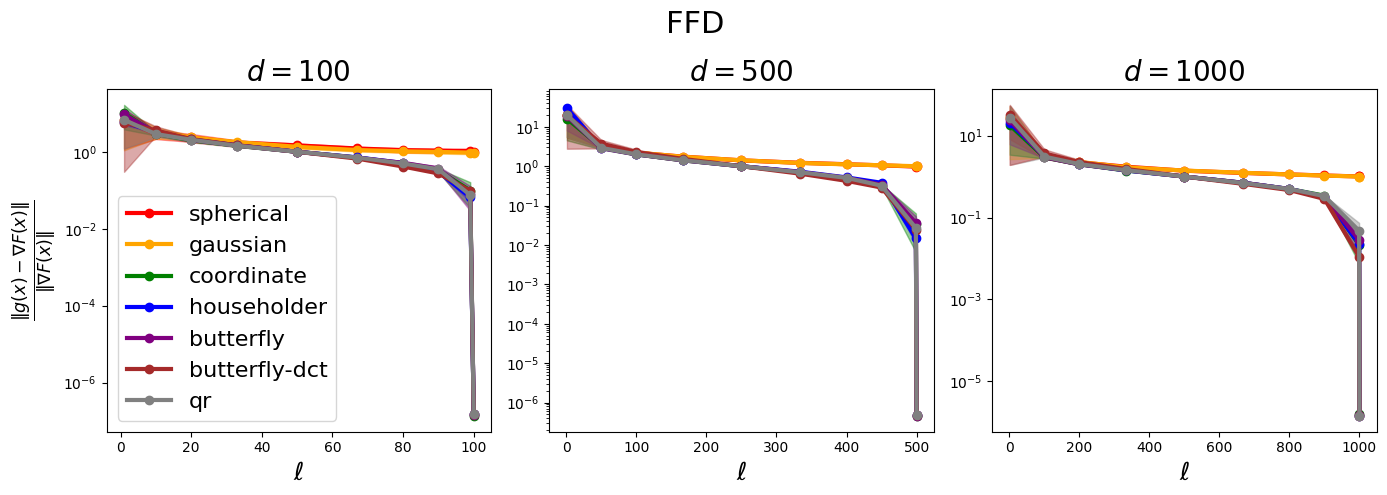

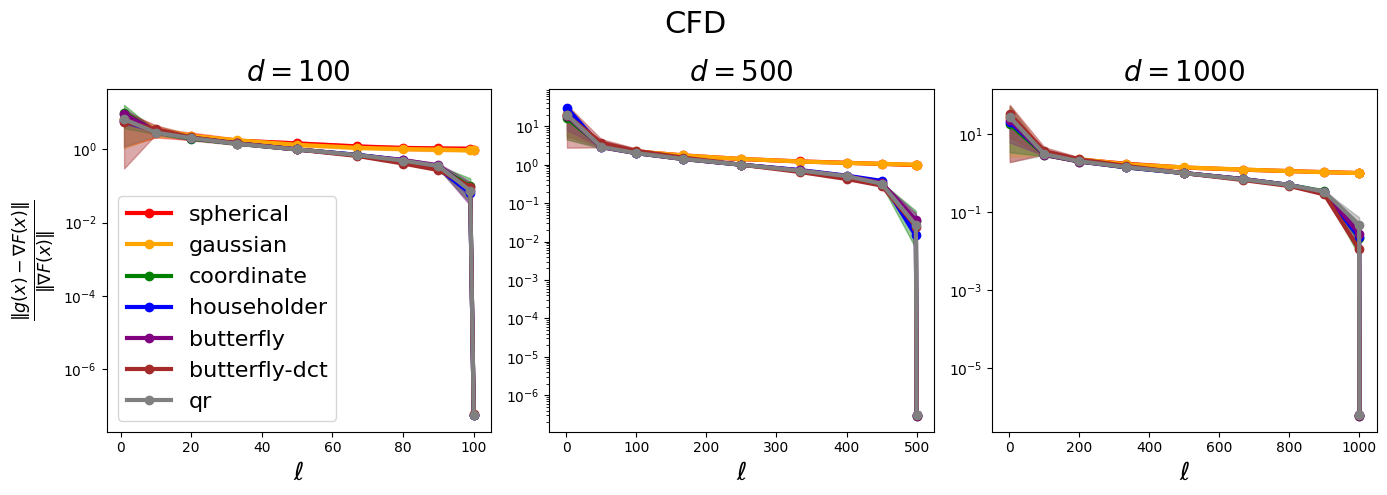

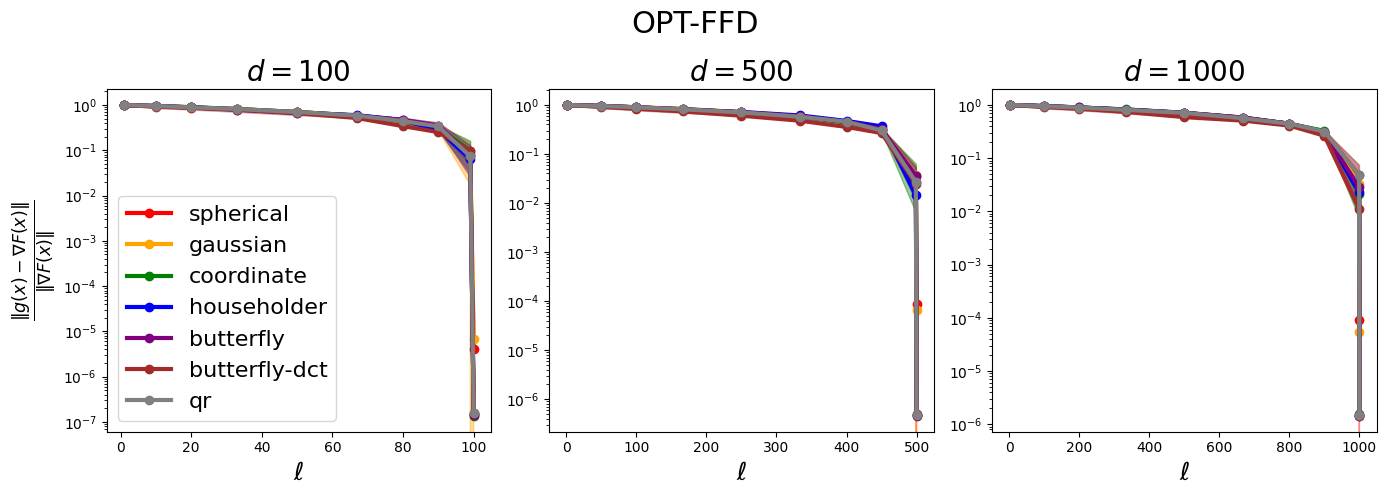

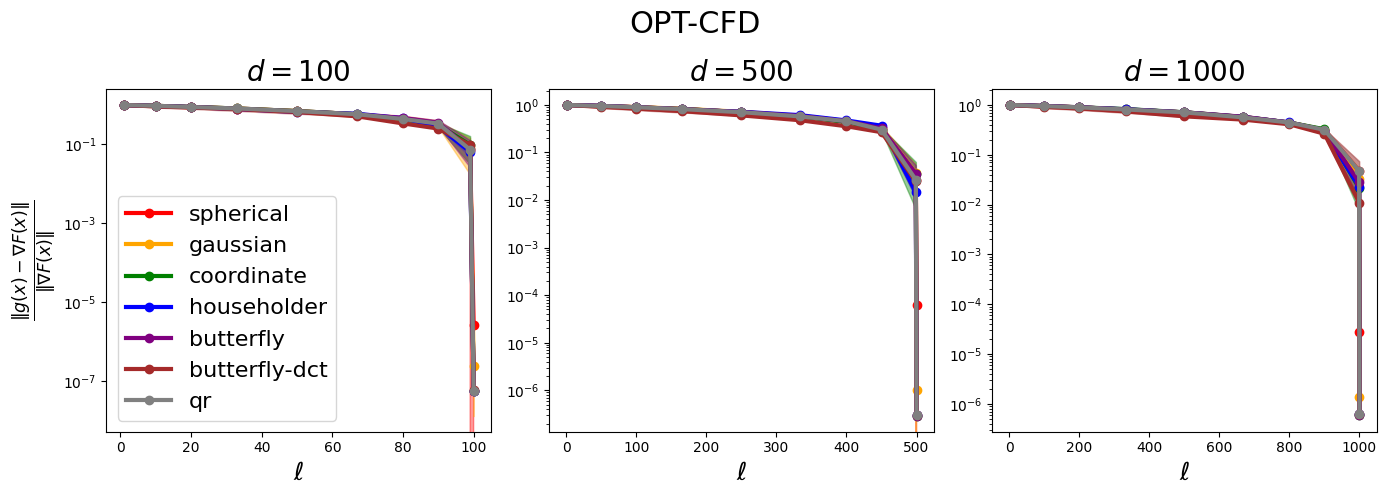

In [6]:
for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
  fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$\ell$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    num_directions = [1, d//10, d//5, d//3, d//2, round((2/3) * d), round((4/5) * d), round((9/10) * d), d - 1, d ]# list(range(1, d, 2)) + [d]
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for l in num_directions:
        data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append( data[data['l'] == l]['err'].values)
      mu_err = np.mean(errors, axis=1)
      std_err = np.std(errors, axis=1)
      
      ax.plot(num_directions, mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
      ax.fill_between(num_directions, mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    if i == 0:
      ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/LS_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

#### Computational time (for l = d)

In [72]:
L, mu = 100.0, 1.0
h = 1e-7

dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/comp_time"
os.makedirs(out_dir, exist_ok=True)

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


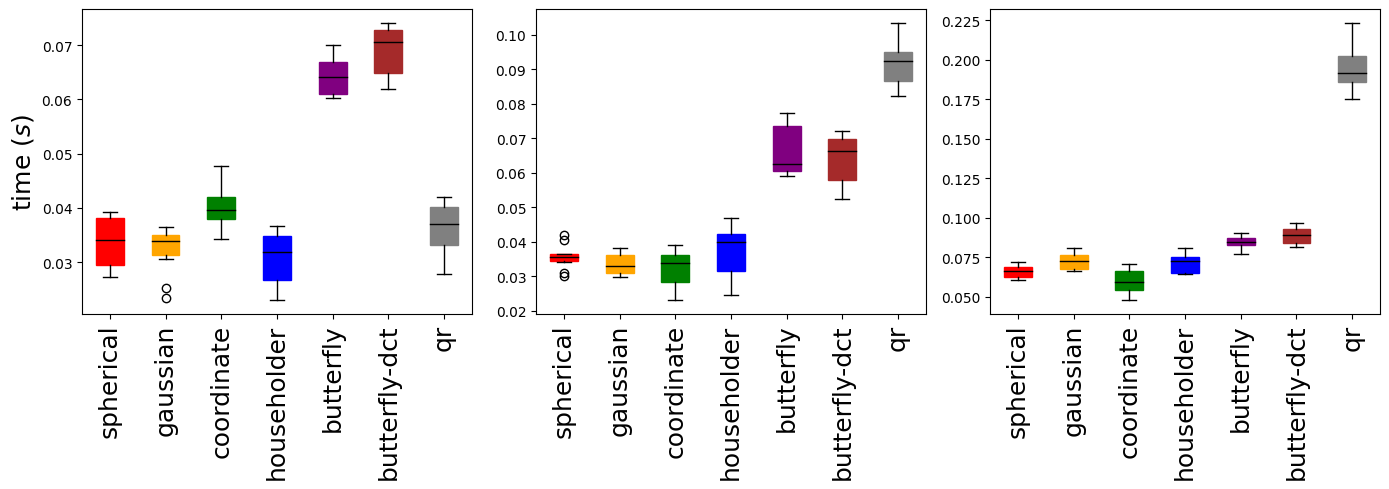

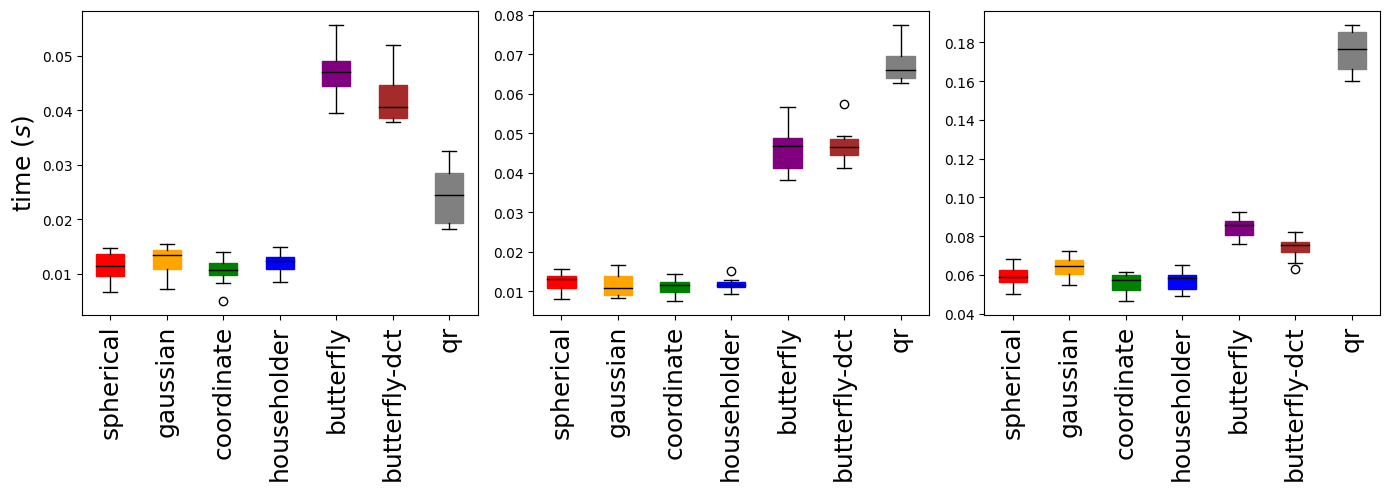

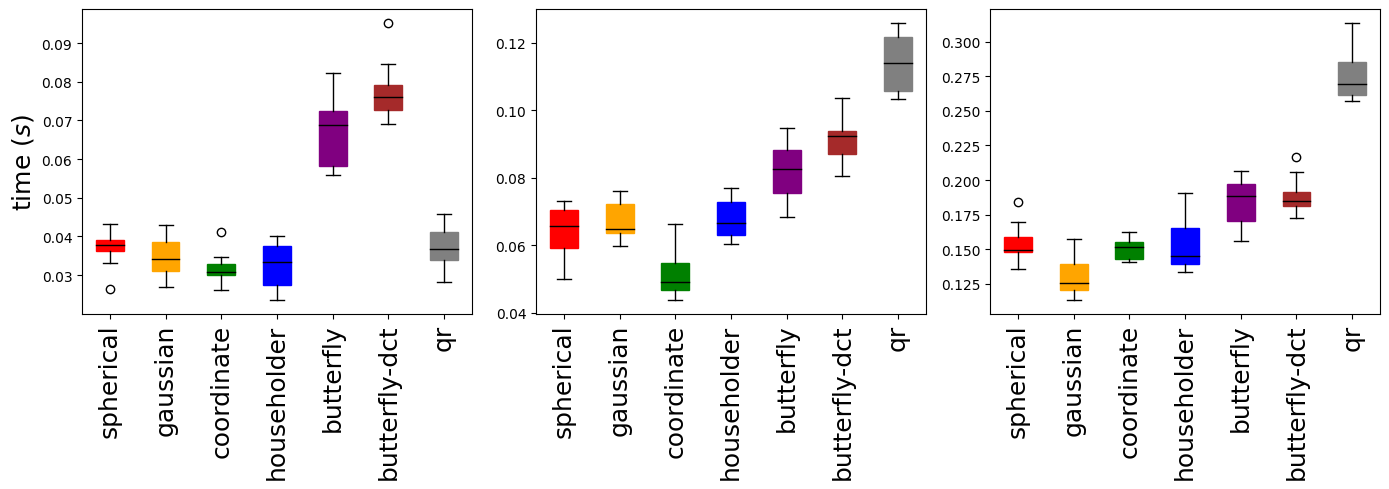

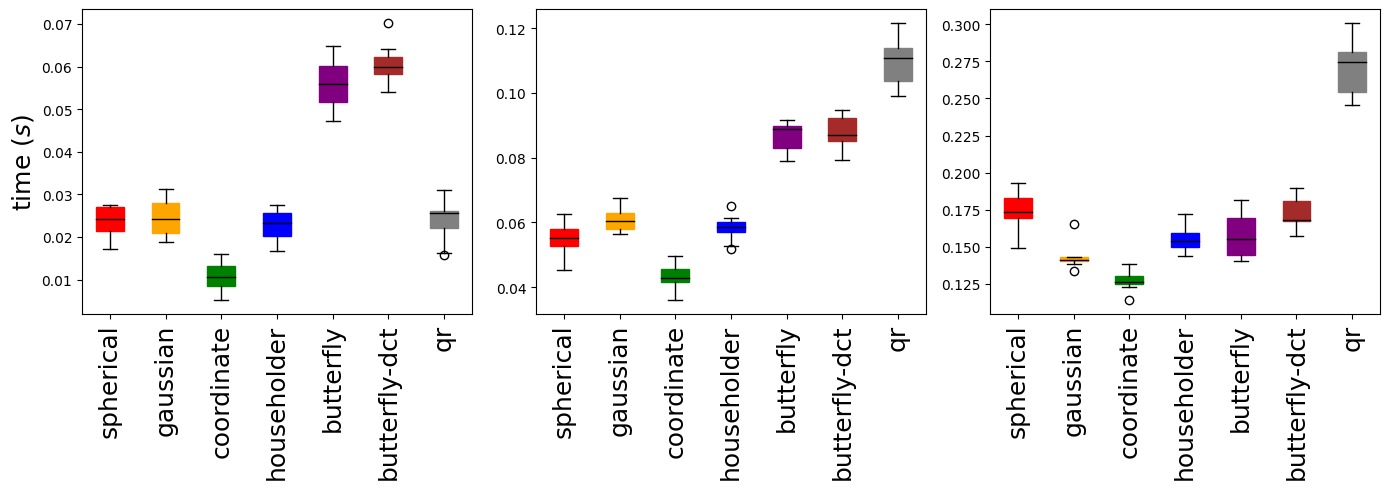

In [73]:
for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
  #fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    if i == 0:
      ax.set_ylabel("time ($s$)", fontsize=18)
    boxes = []
    times = []
    for (d_id, dir_type) in enumerate(direction_type):
      data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)
      data = data[data['directions'] == dir_type]
      times.append( data[data['l'] == d]['time'].values)
      
    b = ax.boxplot(times, patch_artist=True)

    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[j])
        b['medians'][j].set_color('black')
    boxes.append(b['boxes'])
#    ax.set_yscale('log')
    ax.set_xticks(range(1, len(direction_type) + 1), [dir_type.replace("_", "-") for dir_type in direction_type], rotation=90, fontsize=18)
#    if i == 0:
#      ax.legend(b['boxes'], direction_type,fontsize=16, loc='upper left')
#    ax.set_ylim([1e-6, 0.5])
  fig.tight_layout()
  fig.savefig(f"{out_dir}/LS_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

#### Changing h (l = d)

In [70]:
L, mu = 100.0, 1.0

dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/h"
os.makedirs(out_dir, exist_ok=True)

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


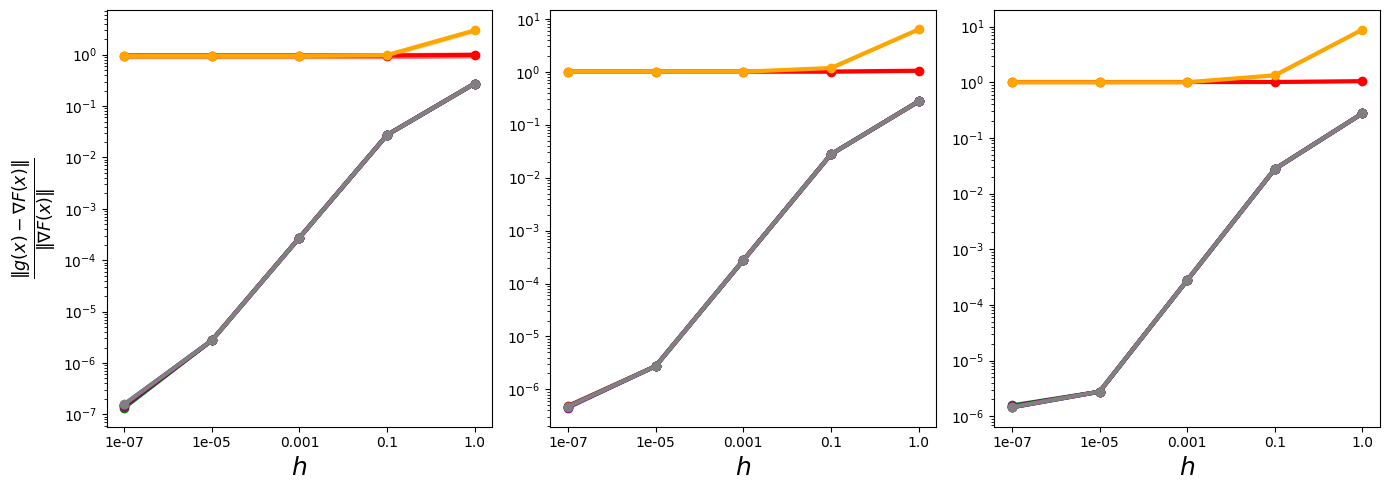

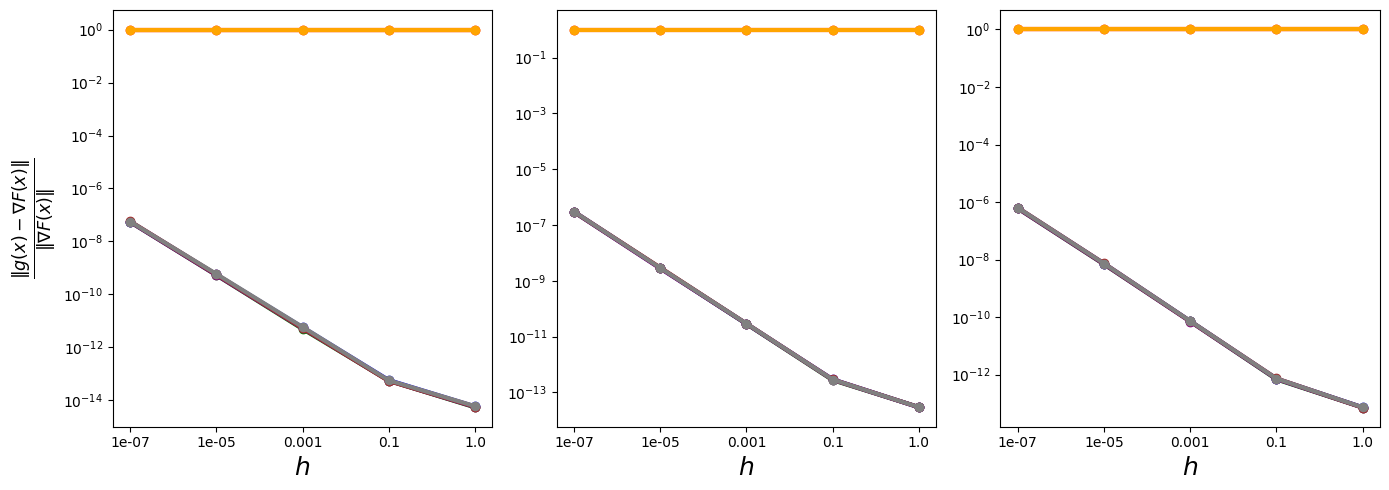

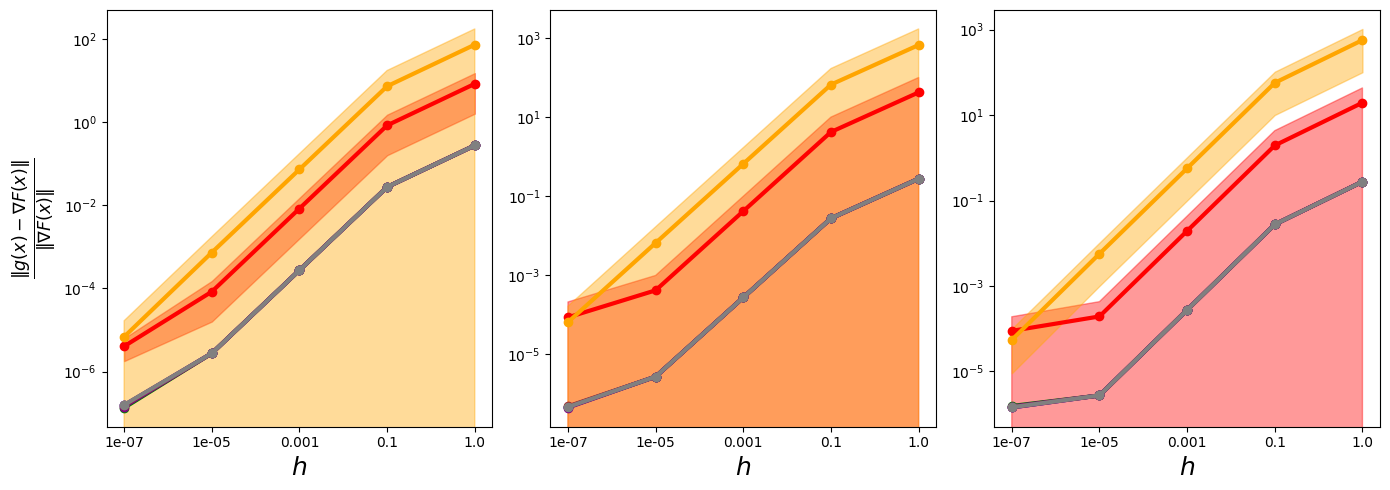

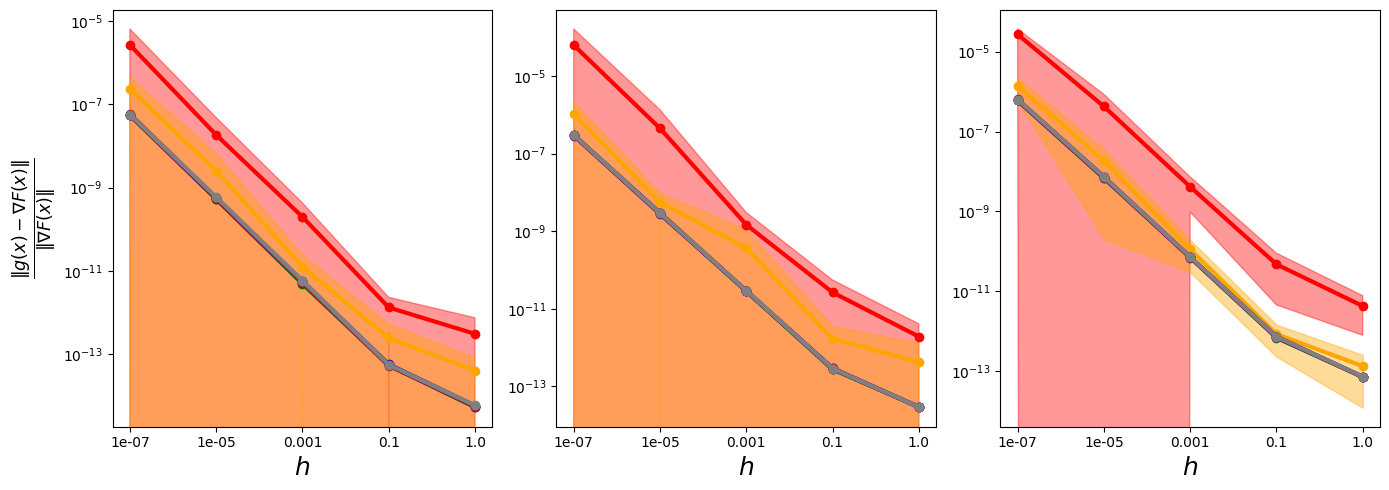

In [71]:
discretizations = [1e-7, 1e-5, 1e-3, 1e-1, 1.0]

for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
  #fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$h$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    boxes = []
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for h in discretizations:
        data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append(data[data['l'] == d]['err'].values)
      mu_err = np.mean(errors, axis=1)
      std_err = np.std(errors, axis=1)
      
      # b =ax.boxplot(errors, patch_artist=True)
      # for j in range(len(b['boxes'])):
      #   b['boxes'][j].set_color(colors[d_id])
      
      ax.plot(range(mu_err.shape[0]), mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
      ax.fill_between(range(mu_err.shape[0]), mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    ax.set_xticks(range(len(discretizations)), discretizations)
 #   if i == 0:
 #     ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/LS_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

#### Changing L

In [62]:
L, mu = 100.0, 1.0
h = 1e-7
dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/L"
os.makedirs(out_dir, exist_ok=True)

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


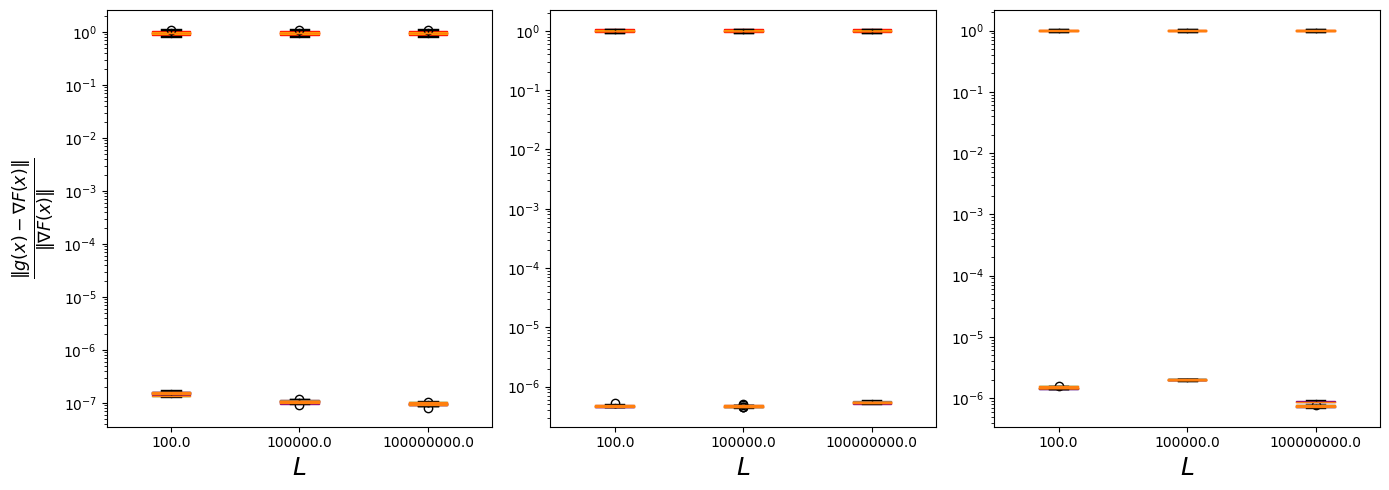

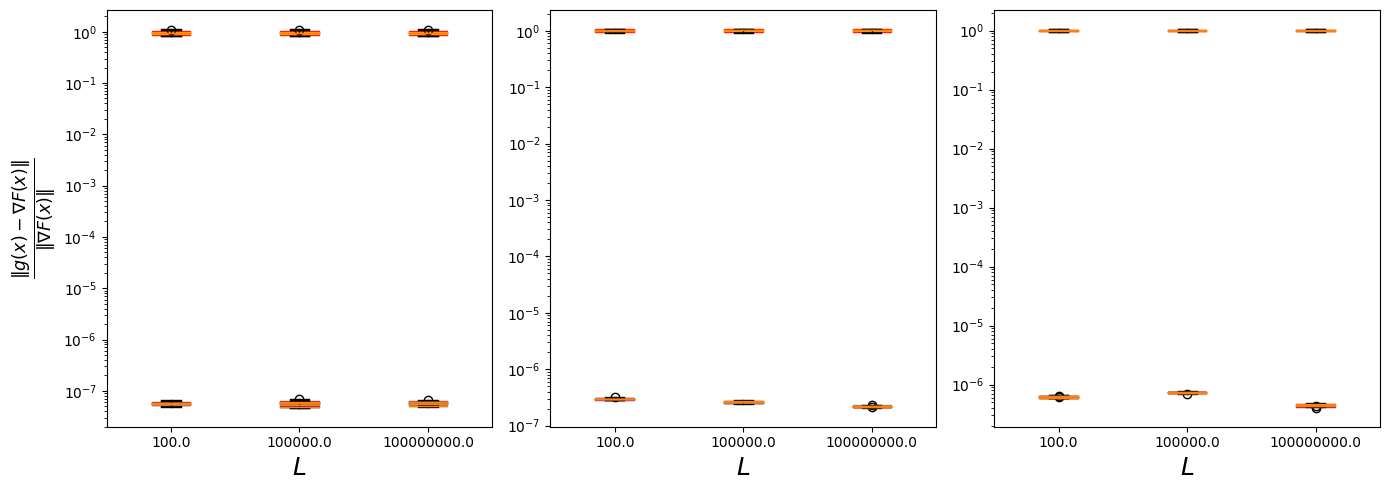

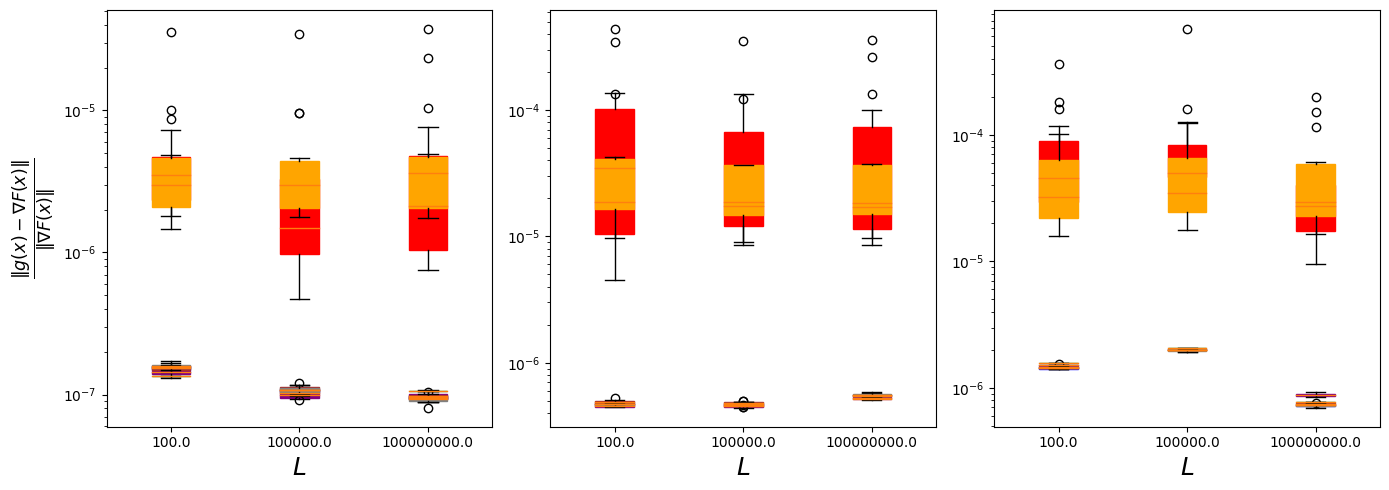

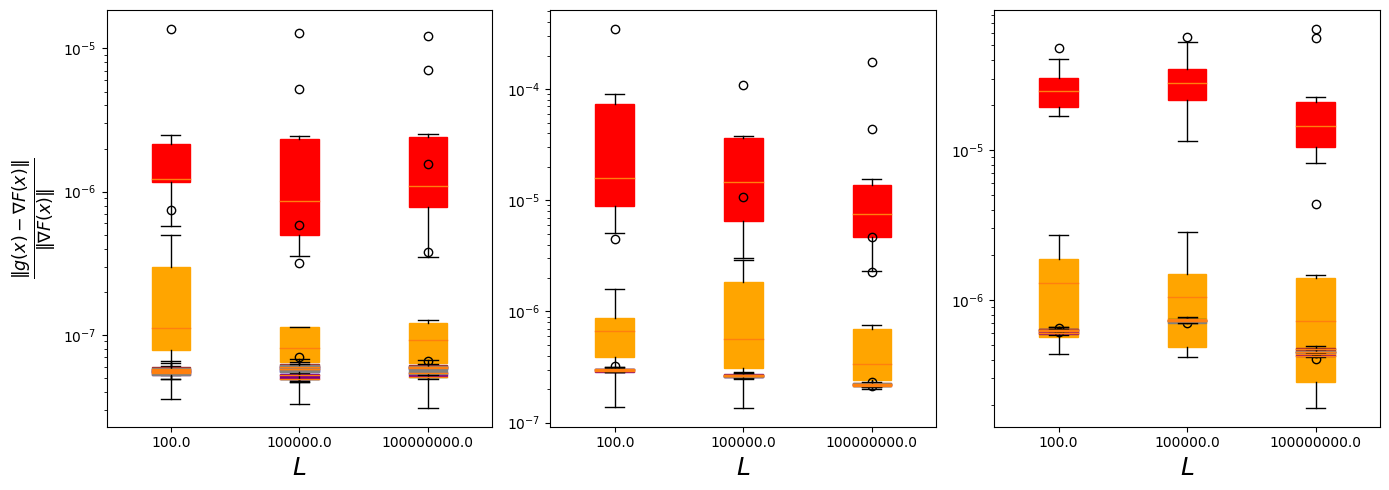

In [67]:
for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
 # fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$L$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    boxes = []
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for L in [100.0, 100000.0, 100000000.0]:
        data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append(data[data['l'] == d]['err'].values)
#      mu_err = np.mean(errors, axis=1)
#      std_err = np.std(errors, axis=1)
      
      b =ax.boxplot(errors, patch_artist=True)
      for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[d_id])
 #     ax.plot(range(mu_err.shape[0]), mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
 #     ax.fill_between(range(mu_err.shape[0]), mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    ax.set_xticks(range(1, 4), [100.0, 100000.0, 100000000.0])
 #   if i == 0:
 #     ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/LS_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

#### Changing $\mu$

In [68]:
h = 1e-7
dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/mu"
os.makedirs(out_dir, exist_ok=True)

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


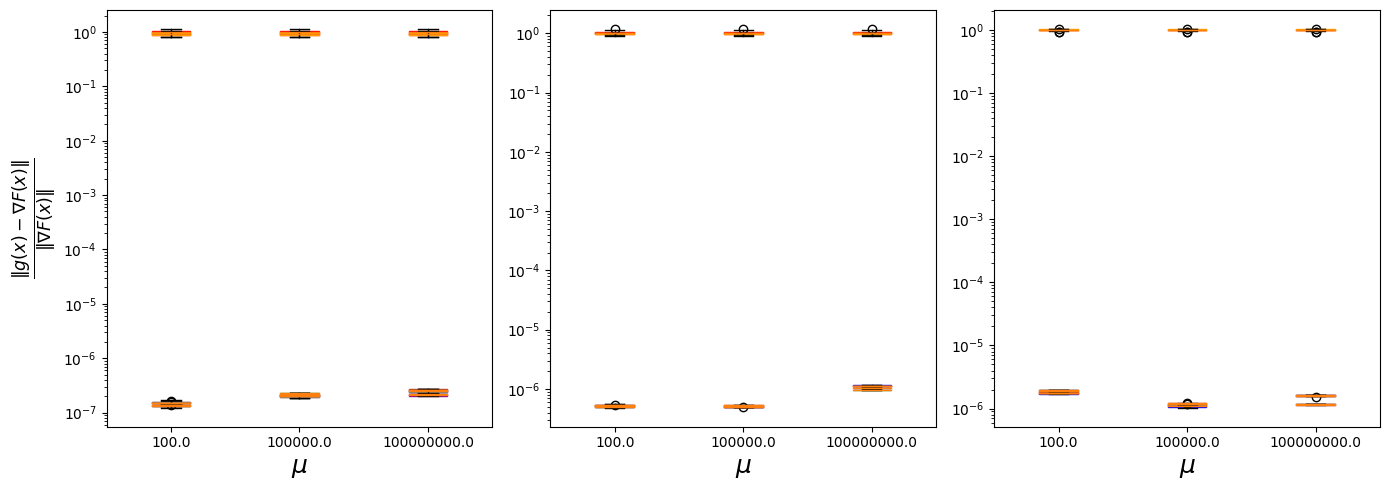

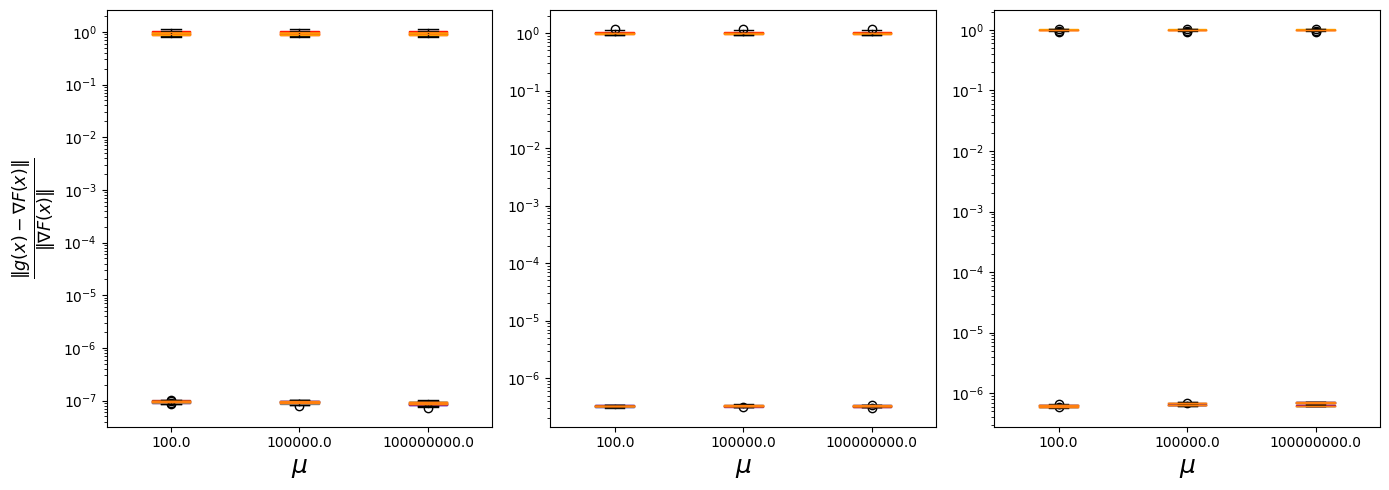

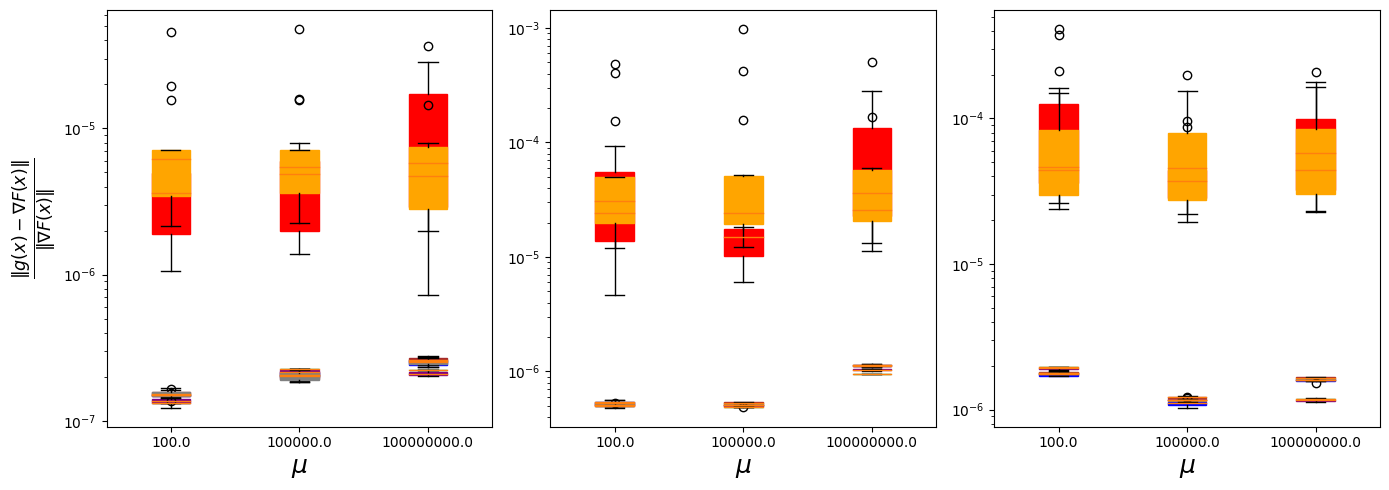

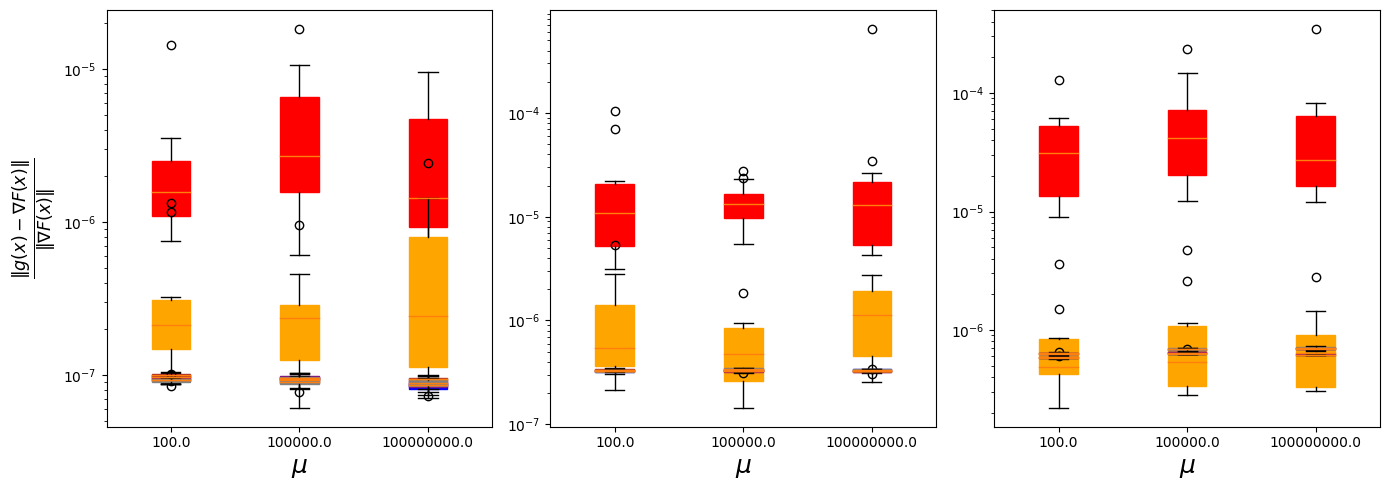

In [69]:
for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
#  fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$\\mu$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    boxes = []
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for mu in [100.0, 100000.0, 100000000.0]:
        data = read_ls_results(data_dir, method, d=d,L=mu + 1.0, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append(data[data['l'] == d]['err'].values)
#      mu_err = np.mean(errors, axis=1)
#      std_err = np.std(errors, axis=1)
      
      b =ax.boxplot(errors, patch_artist=True)
      for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[d_id])
 #     ax.plot(range(mu_err.shape[0]), mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
 #     ax.fill_between(range(mu_err.shape[0]), mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    ax.set_xticks(range(1, 4), [100.0, 100000.0, 100000000.0])
 #   if i == 0:
 #     ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/LS_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

## Synthetic Function

In [101]:
base_out_dir = "./plots/approx_error/synthetic"
os.makedirs(base_out_dir, exist_ok=True)


[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


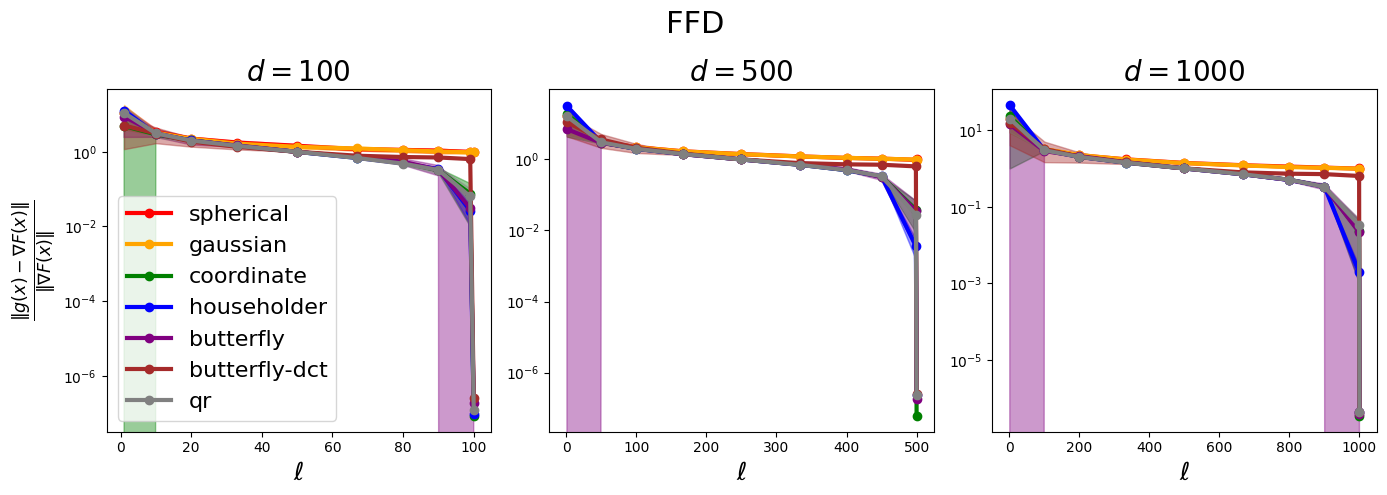

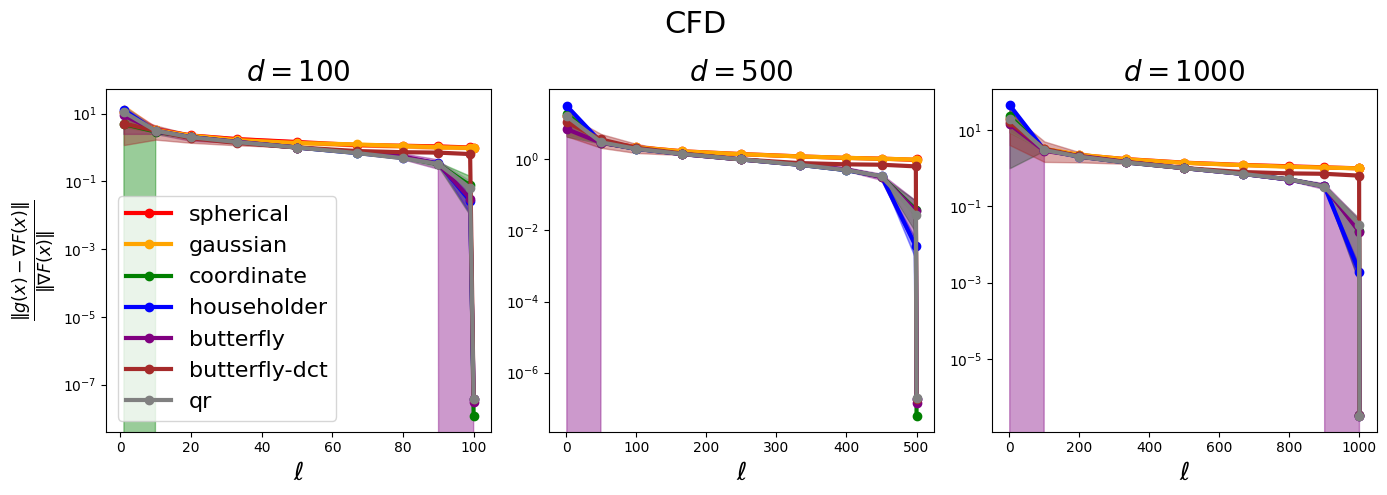

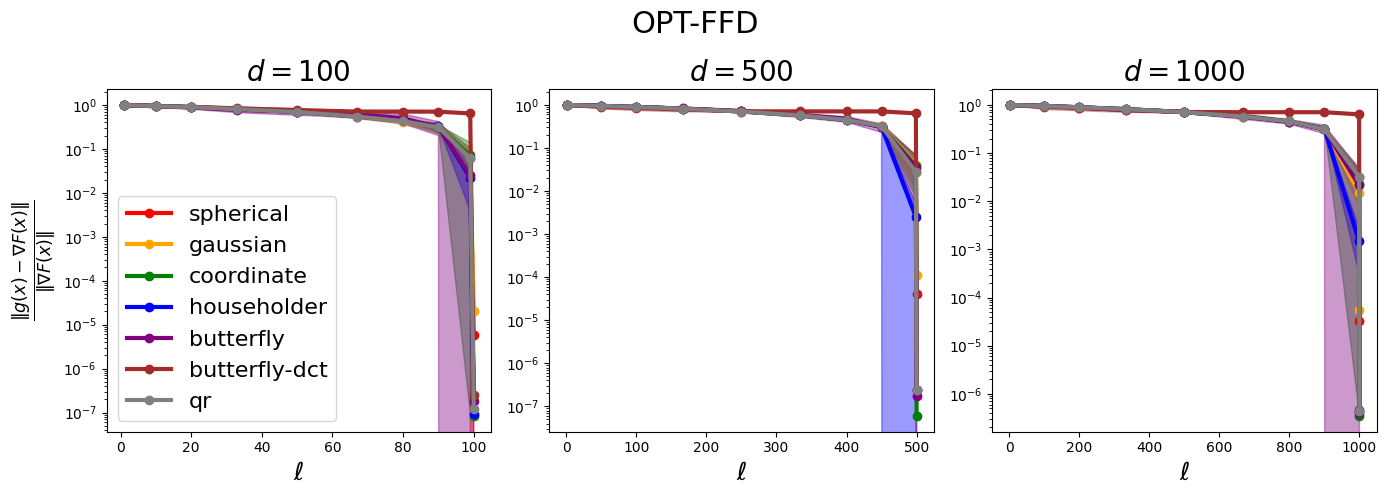

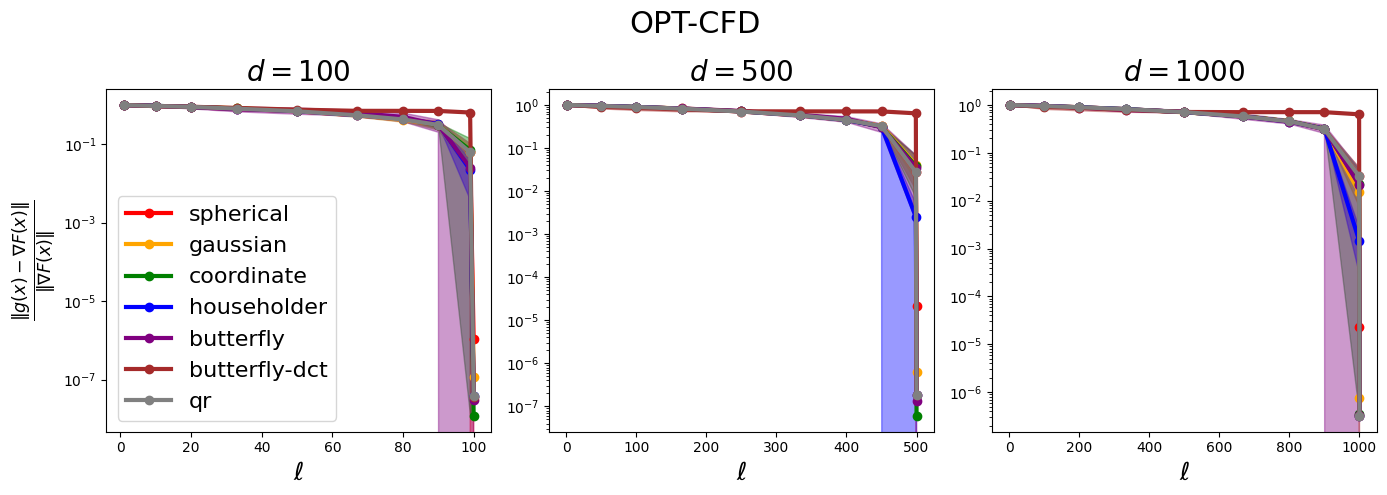

In [102]:
L, mu = 100.0, 1.0
h = 1e-7

dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/changing_l"
os.makedirs(out_dir, exist_ok=True)
for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
  fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$\ell$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    num_directions = [1, d//10, d//5, d//3, d//2, round((2/3) * d), round((4/5) * d), round((9/10) * d), d - 1, d ]# list(range(1, d, 2)) + [d]
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for l in num_directions:
        data = read_syn_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append( data[data['l'] == l]['err'].values)
      mu_err = np.mean(errors, axis=1)
      std_err = np.std(errors, axis=1)
      
      ax.plot(num_directions, mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
      ax.fill_between(num_directions, mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    if i == 0:
      ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/SYN_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


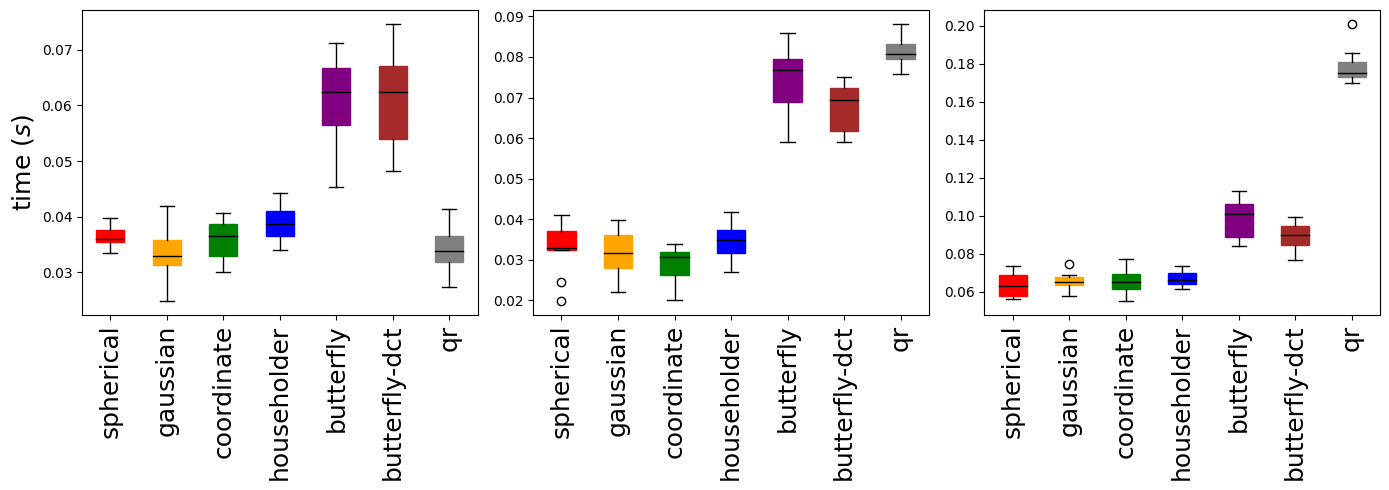

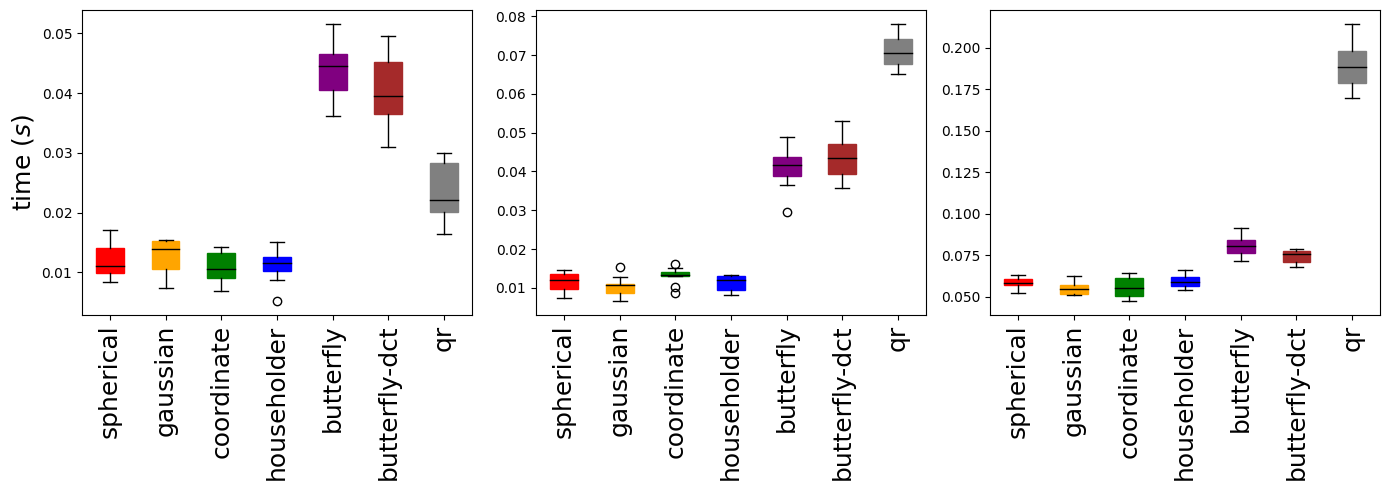

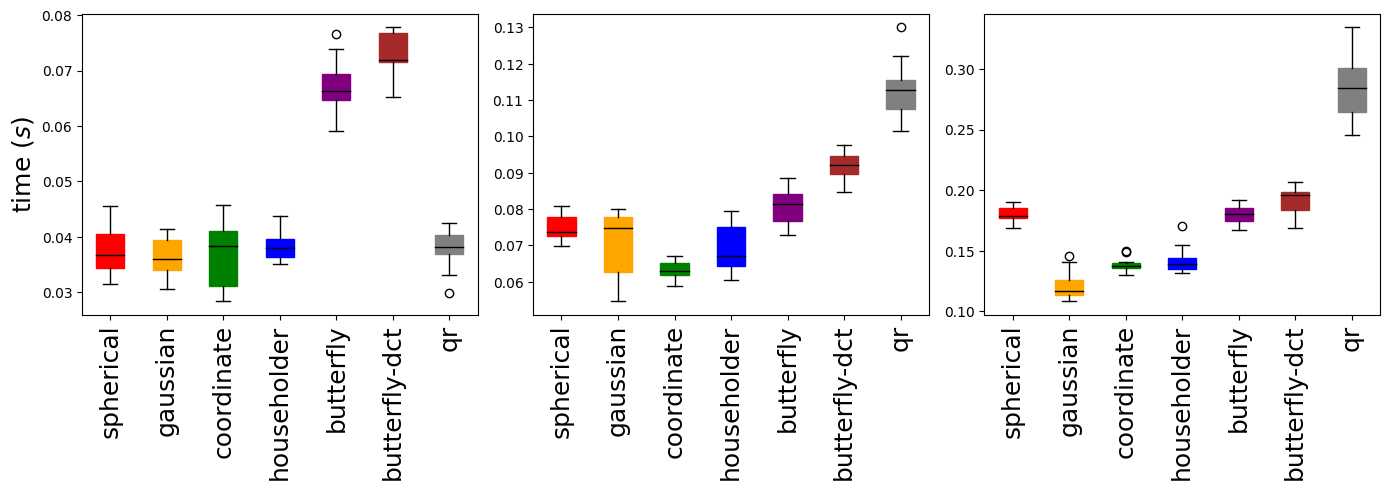

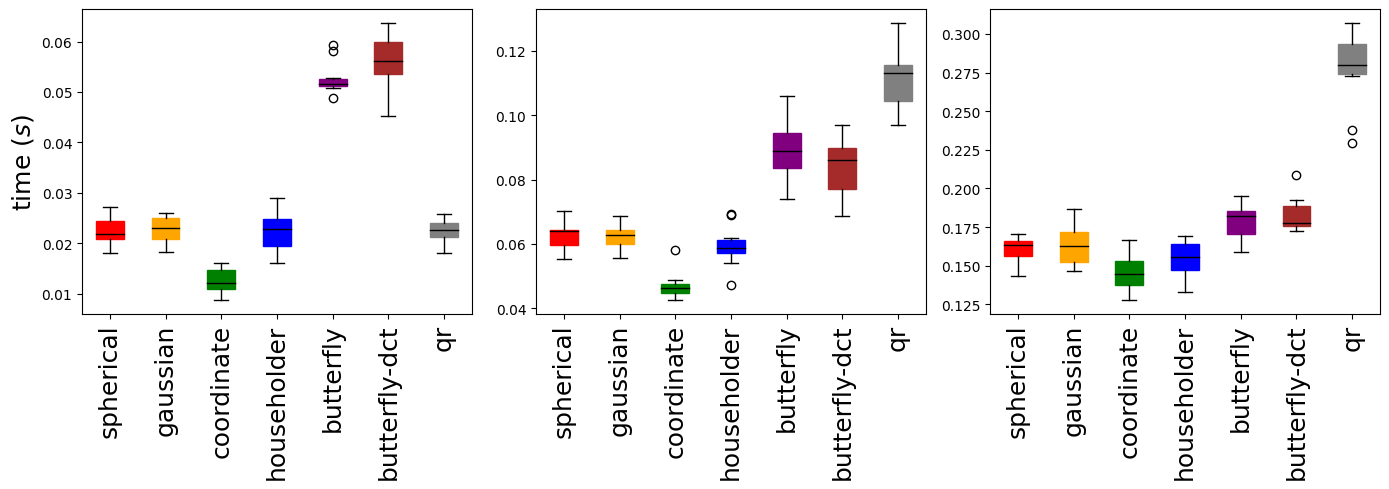

In [105]:
L, mu = 100.0, 1.0
h = 1e-7

dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/comp_time"
os.makedirs(out_dir, exist_ok=True)

for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
  #fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    if i == 0:
      ax.set_ylabel("time ($s$)", fontsize=18)
    boxes = []
    times = []
    for (d_id, dir_type) in enumerate(direction_type):
      data = read_syn_results(data_dir, method, d=d,L=L, mu=mu, h=h)
      data = data[data['directions'] == dir_type]
      times.append( data[data['l'] == d]['time'].values)
      
    b = ax.boxplot(times, patch_artist=True)

    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[j])
        b['medians'][j].set_color('black')
    boxes.append(b['boxes'])
#    ax.set_yscale('log')
    ax.set_xticks(range(1, len(direction_type) + 1), [dir_type.replace("_", "-") for dir_type in direction_type], rotation=90, fontsize=18)
#    if i == 0:
#      ax.legend(b['boxes'], direction_type,fontsize=16, loc='upper left')
#    ax.set_ylim([1e-6, 0.5])
  fig.tight_layout()
  fig.savefig(f"{out_dir}/SYN_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


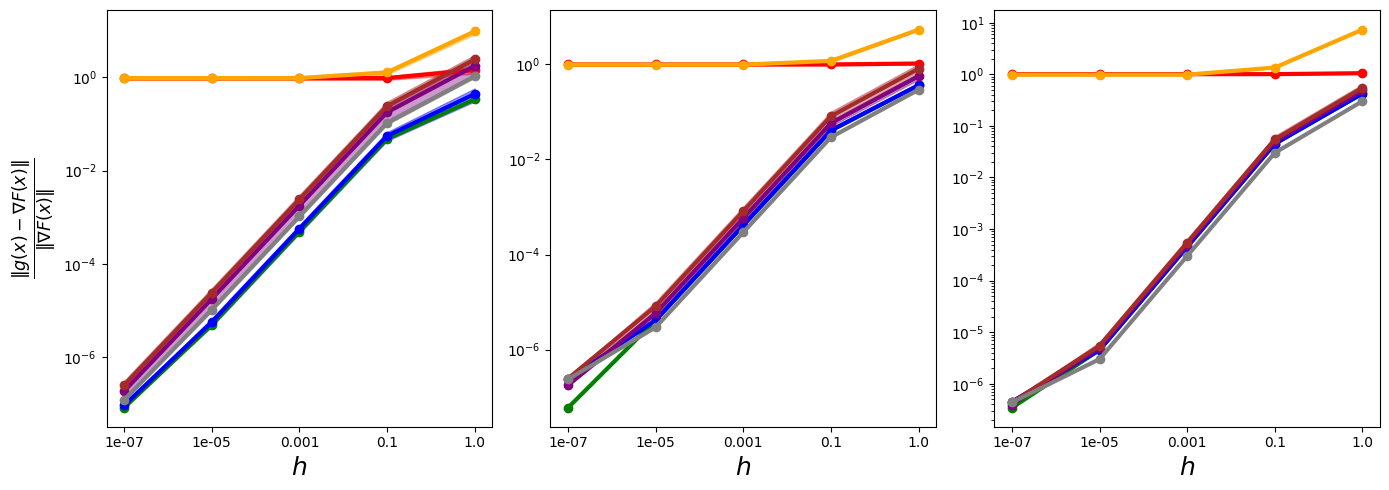

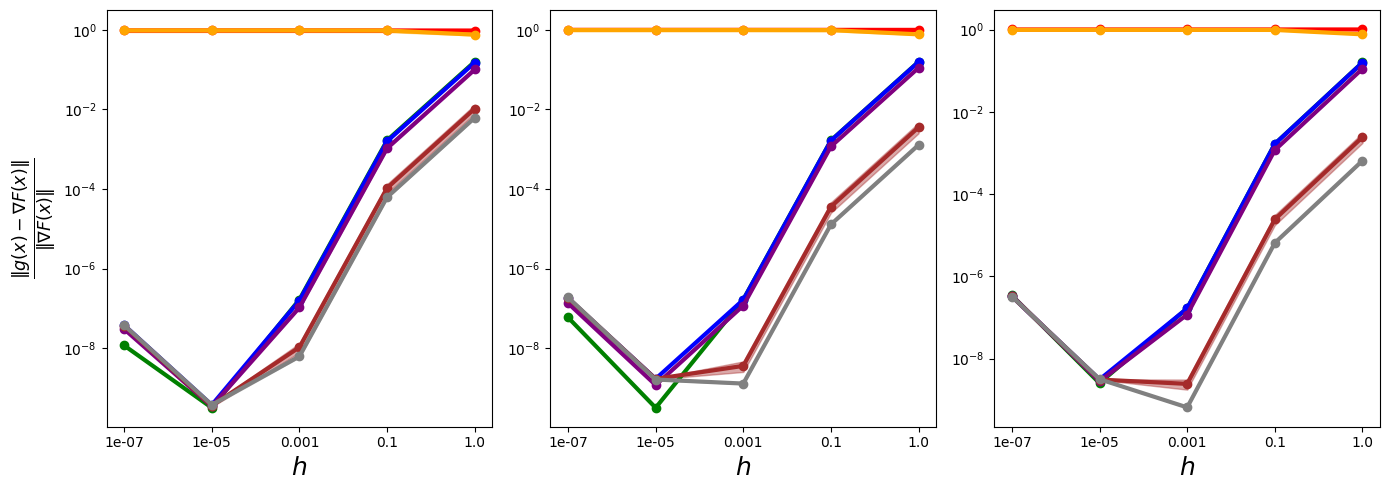

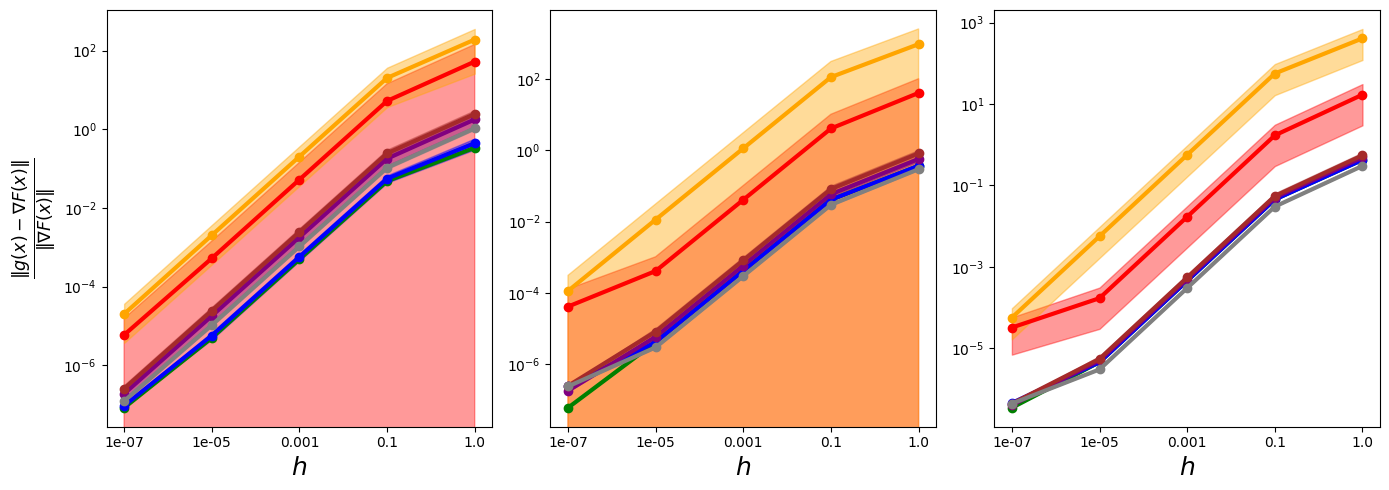

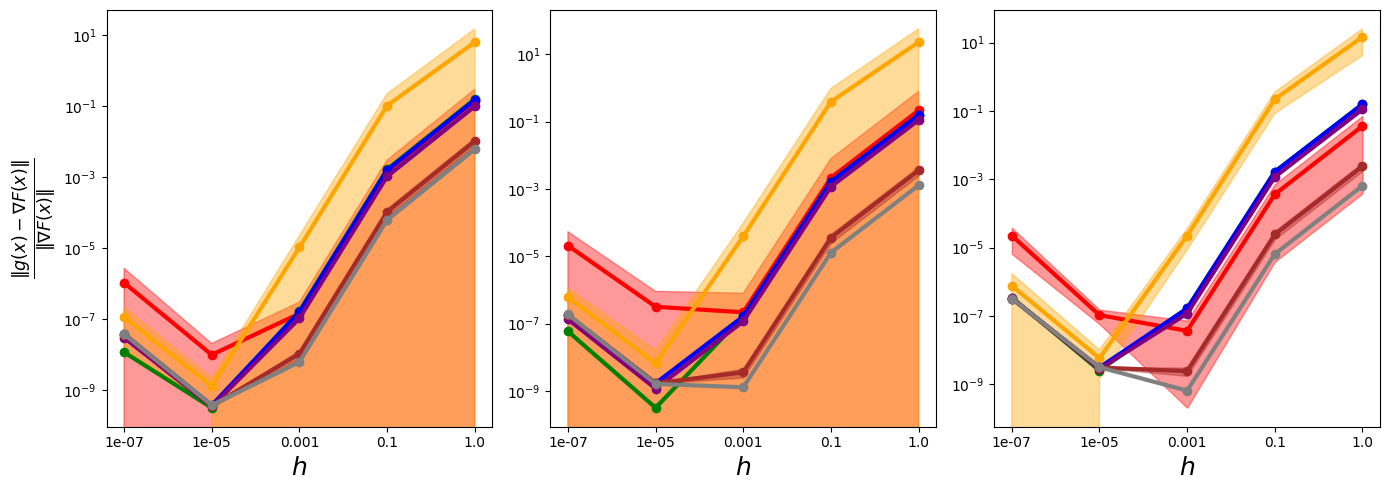

In [104]:
L, mu = 100.0, 1.0

dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/h"
os.makedirs(out_dir, exist_ok=True)


discretizations = [1e-7, 1e-5, 1e-3, 1e-1, 1.0]

for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
  #fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$h$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    boxes = []
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for h in discretizations:
        data = read_syn_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append(data[data['l'] == d]['err'].values)
      mu_err = np.mean(errors, axis=1)
      std_err = np.std(errors, axis=1)
      
      # b =ax.boxplot(errors, patch_artist=True)
      # for j in range(len(b['boxes'])):
      #   b['boxes'][j].set_color(colors[d_id])
      
      ax.plot(range(mu_err.shape[0]), mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
      ax.fill_between(range(mu_err.shape[0]), mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    ax.set_xticks(range(len(discretizations)), discretizations)
 #   if i == 0:
 #     ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/SYN_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


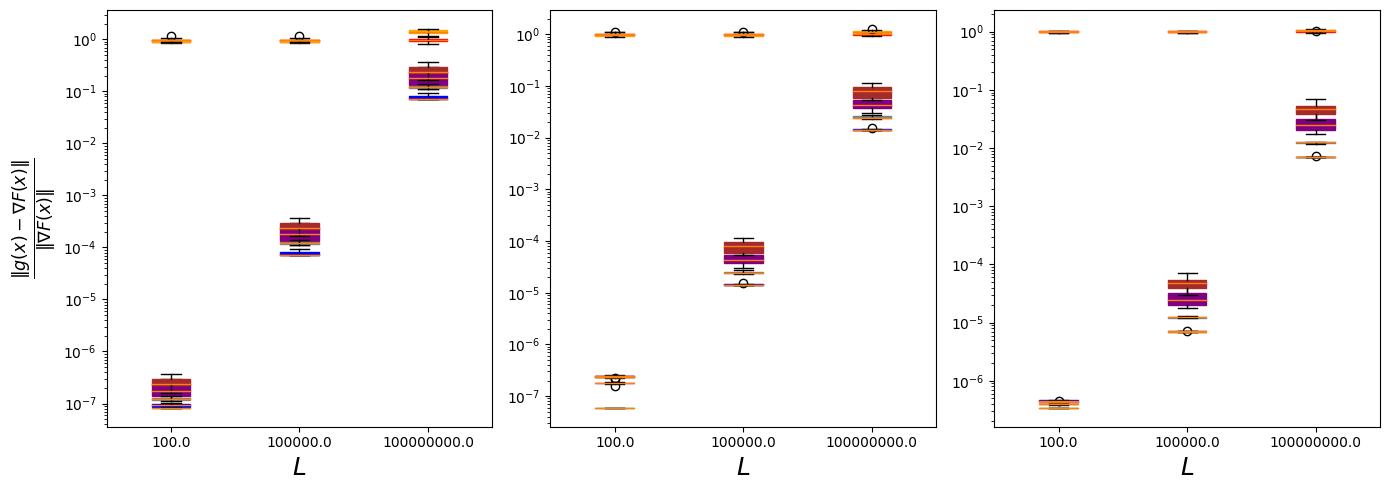

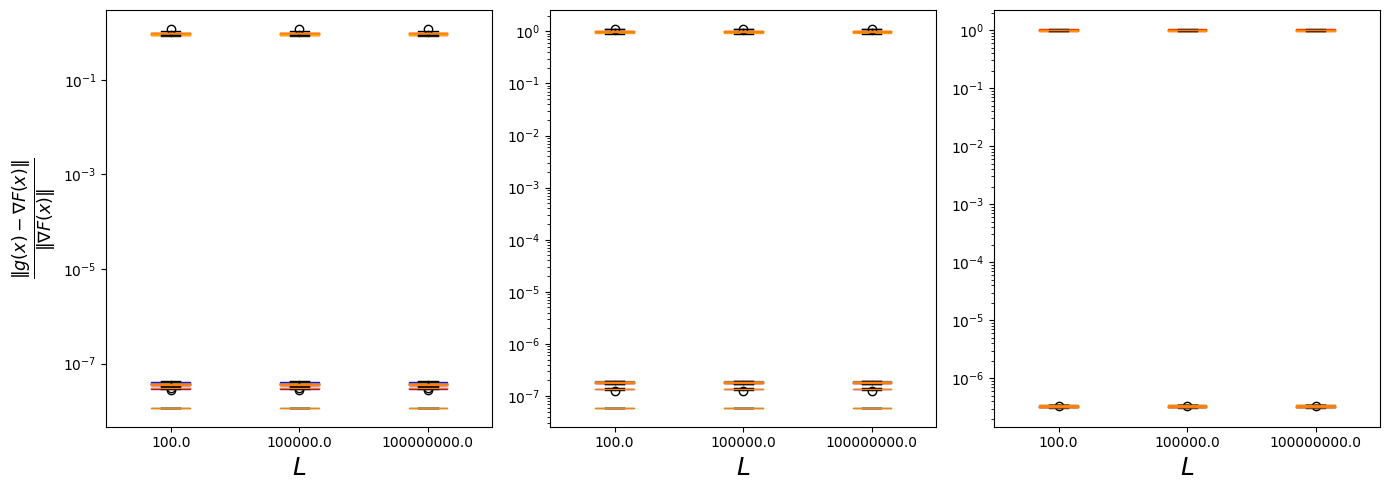

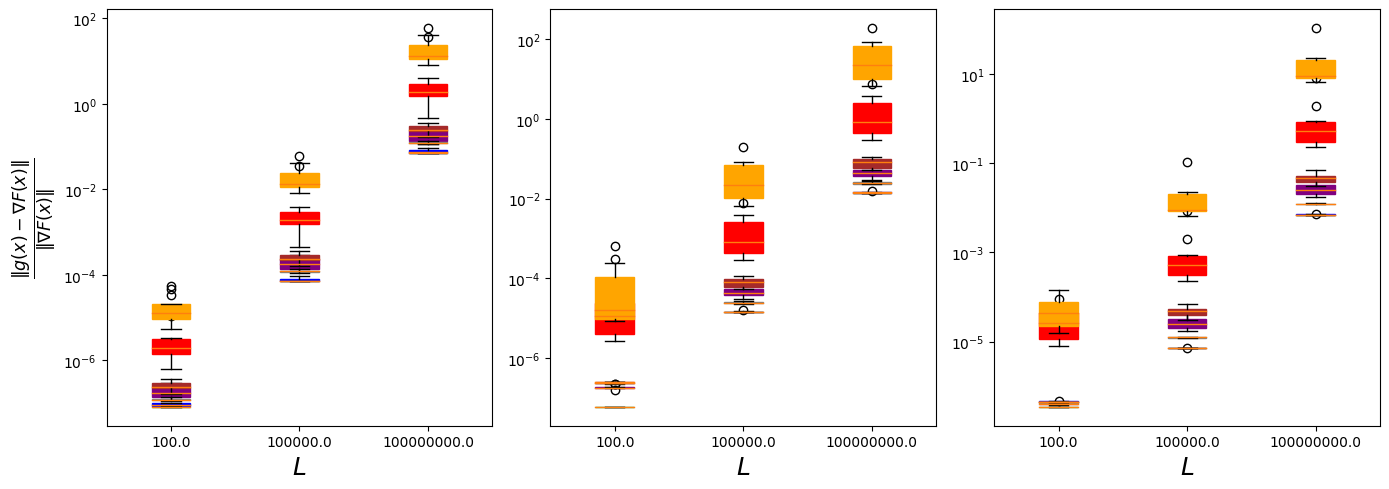

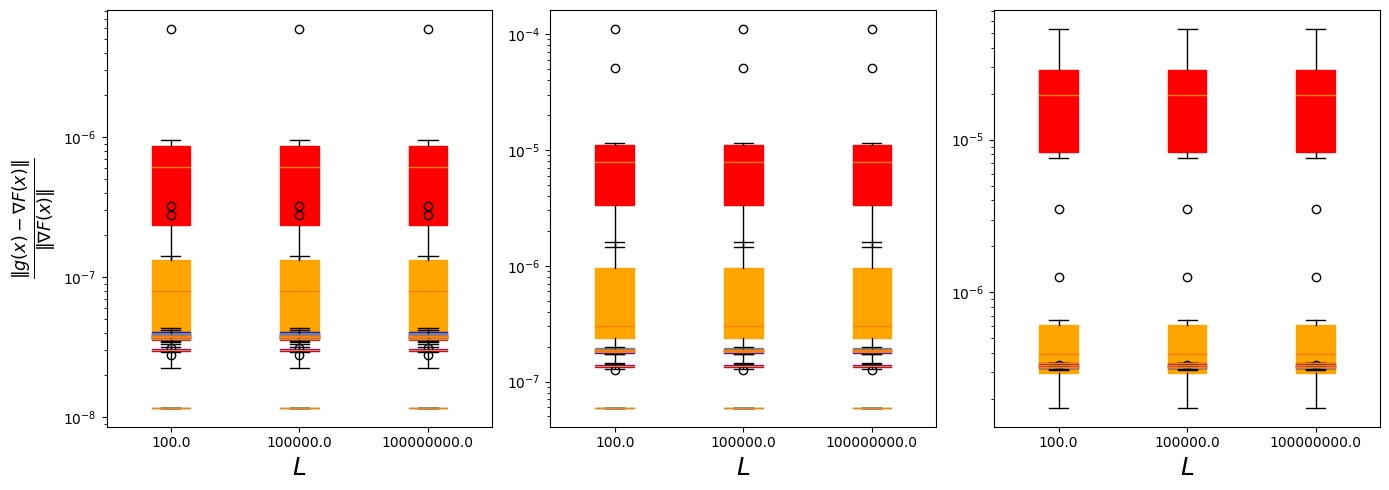

In [106]:
L, mu = 100.0, 1.0
h = 1e-7
dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/L"
os.makedirs(out_dir, exist_ok=True)


for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
 # fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$L$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    boxes = []
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for L in [100.0, 100000.0, 100000000.0]:
        data = read_syn_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append(data[data['l'] == d]['err'].values)
#      mu_err = np.mean(errors, axis=1)
#      std_err = np.std(errors, axis=1)
      
      b =ax.boxplot(errors, patch_artist=True)
      for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[d_id])
 #     ax.plot(range(mu_err.shape[0]), mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
 #     ax.fill_between(range(mu_err.shape[0]), mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    ax.set_xticks(range(1, 4), [100.0, 100000.0, 100000000.0])
 #   if i == 0:
 #     ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/SYN_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

[--] Completed for ffd
[--] Completed for cfd
[--] Completed for opt_ffd
[--] Completed for opt_cfd


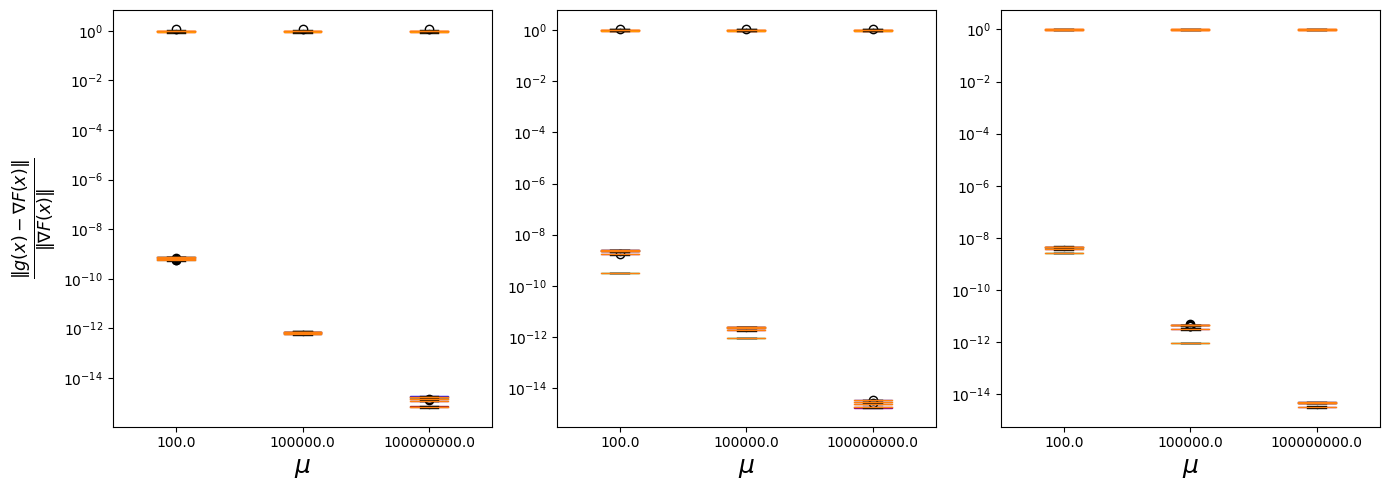

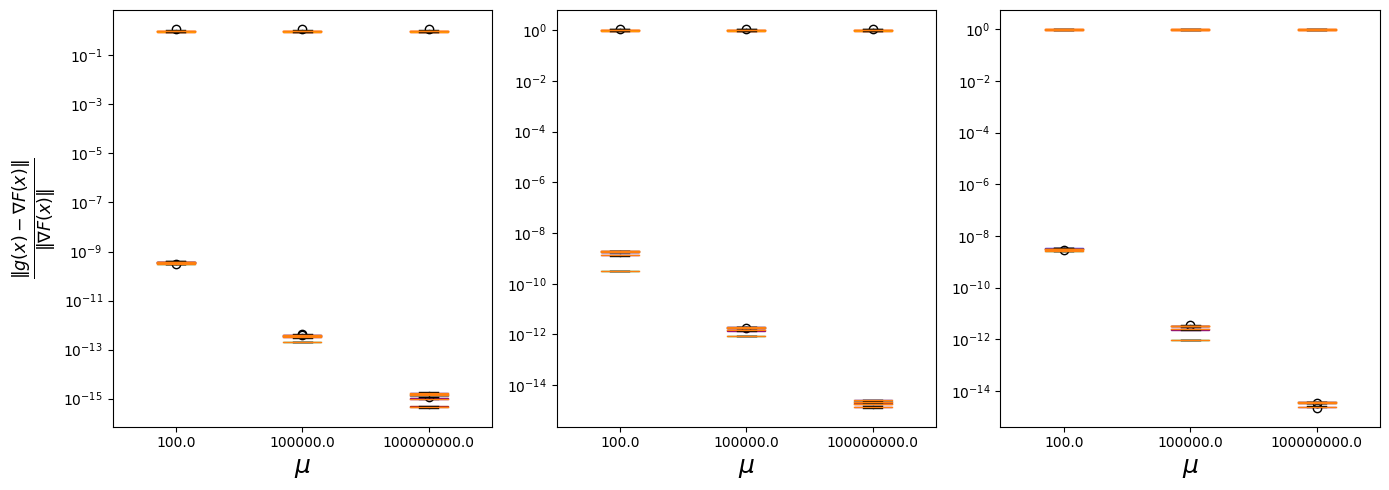

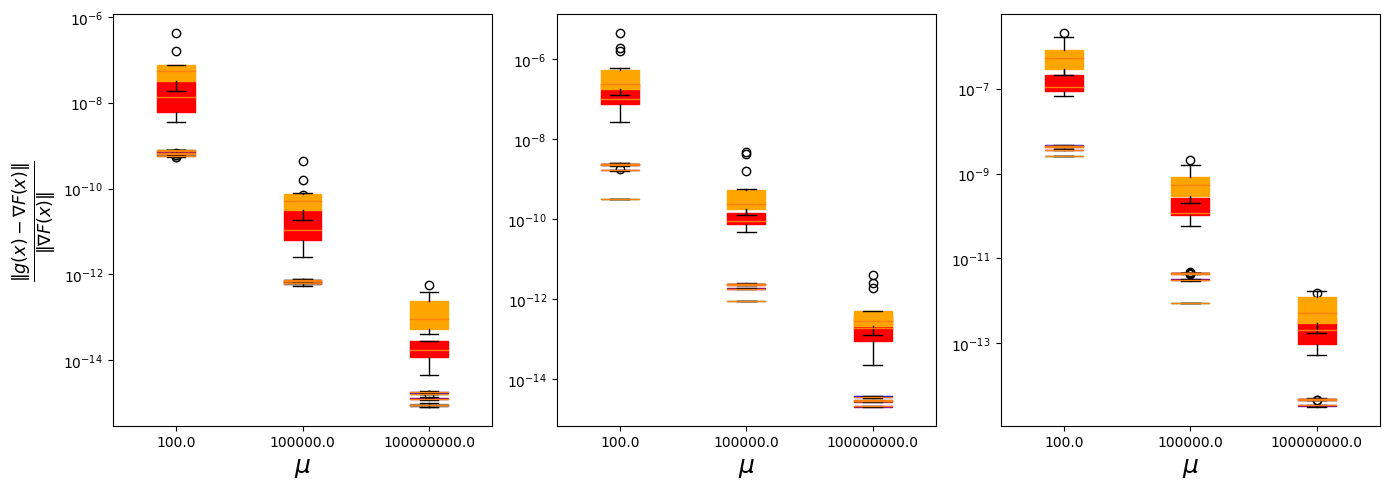

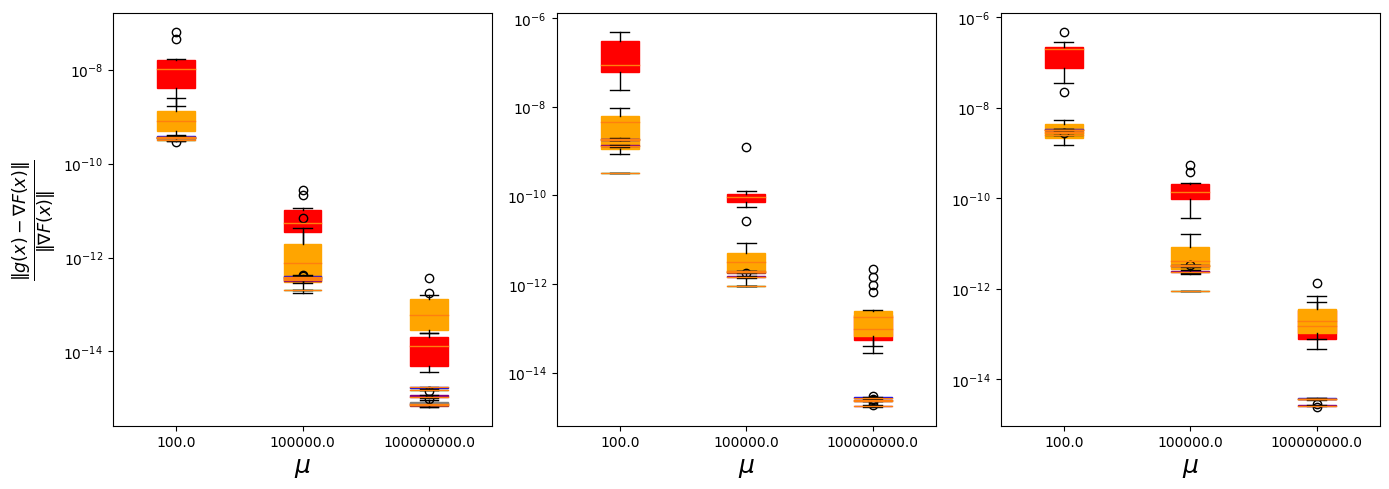

In [110]:
h = 1e-7
dimensions = [100, 500, 1000]
out_dir = f"{base_out_dir}/mu"
os.makedirs(out_dir, exist_ok=True)

for method in methods:
  fig, axes = plt.subplots(1, 3, figsize=(14, 5))
#  fig.suptitle(method.upper().replace("_","-"), fontsize=22)
  for (i, d) in enumerate(dimensions):
    ax = axes[i]
#    ax.set_title("$d = ${}".format(d), fontsize=20)
    ax.set_xlabel("$\\mu$", fontsize=18)
    if i == 0:
      ax.set_ylabel("$\\frac{\| g(x) - \\nabla F(x)\|}{\|\\nabla F(x)\|} $", fontsize=18)
    boxes = []
    for (d_id, dir_type) in enumerate(direction_type):
      errors = []
      for mu in [100.0, 100000.0, 100000000.0]:
        data = read_syn_results(data_dir, method, d=d,L=mu + 1.0, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        errors.append(data[data['l'] == d]['err'].values)
#      mu_err = np.mean(errors, axis=1)
#      std_err = np.std(errors, axis=1)
      
      b =ax.boxplot(errors, patch_artist=True)
      for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[d_id])
 #     ax.plot(range(mu_err.shape[0]), mu_err, 'o-', c=colors[d_id], lw=3, label=dir_type.replace("_","-"), rasterized=True)
 #     ax.fill_between(range(mu_err.shape[0]), mu_err - std_err, mu_err + std_err, alpha=0.4, color=colors[d_id], rasterized=True)
    ax.set_yscale('log')
    ax.set_xticks(range(1, 4), [100.0, 100000.0, 100000000.0])
 #   if i == 0:
 #     ax.legend(fontsize=16)

  fig.tight_layout()
  fig.savefig(f"{out_dir}/SYN_{method}.pdf", bbox_inches='tight')
#  plt.close(fig)
  print(f"[--] Completed for {method}")

# Stepsize Comparison

In [57]:
data_dir = "/data/mrando/fdopt_results/stepsize/noise_0.0"
methods = ['ffd', 'cfd', 'opt_ffd', 'opt_cfd']
direction_type = ['spherical', 'gaussian', 'coordinate', 'householder', 'butterfly',  'qr']
gammas = np.logspace(-5, -1, 100)

num_directions = [1, d//2, round((2/3) * d), round((4/5) * d), round((9/10) * d), d ]
num_dirs_label = ["1", "d/2", "2/3 d", "4/5 d", "9/10 d", 'd']


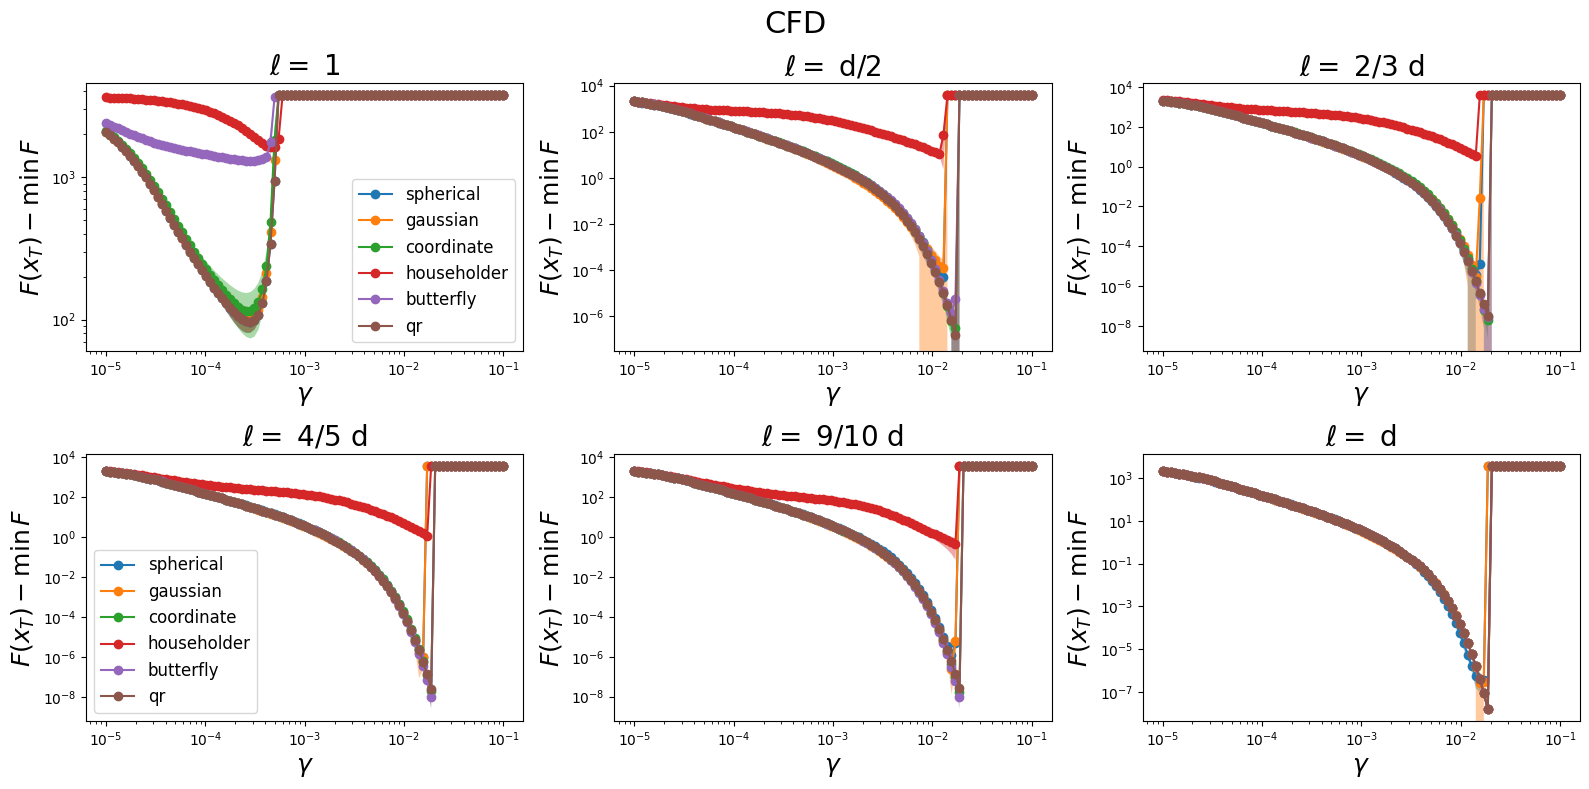

In [65]:
d = 100


for method in ['cfd']:
  data =pd.read_csv(f"{data_dir}/{method}/tolerance/LeastSquares_{d}_100.0_1.0_1e-07.csv")
  

  fig, axes = plt.subplots(2, 3, figsize=(16, 8))
  fig.suptitle(method.upper().replace("_","-"), fontsize=22)

  axes = axes.flatten()
  for i in range(len(num_directions)):
    ax = axes[i]
    ax.set_title(f"$\ell = $ {num_dirs_label[i]}", fontsize=20)
    
    data_d = data[data['l'] == num_directions[i]]
    for dir_type in direction_type:
      mu_val = data_d[data_d['directions'] == dir_type]['mu_last_val'].values #/ data[data['directions'] == dir_type]['f_0'].values 
      std_val = data_d[data_d['directions'] == dir_type]['std_last_val'].values
      
      ax.plot(gammas, mu_val, 'o-', label=dir_type, rasterized=True)
      ax.fill_between(gammas, mu_val - std_val, mu_val + std_val, alpha=0.4)
      
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.set_xlabel("$\gamma$", fontsize=18)
    ax.set_ylabel("$F(x_T) - \\min \\, F$", fontsize=18)
    if i == 0 or i==3:
      ax.legend(fontsize=12)
  fig.tight_layout()
  fig.savefig(f"./stepsize_ls_{d}_{method}.pdf", bbox_inches='tight')

# Linesearch

In [68]:
#data_dir = "./convergence/ris/convergence/noise_0.0/ffd"
methods = ['ffd', 'cfd', 'opt_ffd', 'opt_cfd']
method = methods[0]
data_dir = f"/data/mrando/fdopt_results/convergence/noise_0.0/{method}"
direction_type = ['spherical', 'gaussian', 'rademacher', 'coordinate', 'householder', 'butterfly',  'qr']
gammas = np.logspace(-5, -1, 100)


In [48]:
def read_result(fname):
  values, gammas = [], []
  grad_norms = []
  f_0 = None
  with open(fname, 'r') as f:
    lines = f.readlines()
    for line in lines:
      splitted = line.split(',')
      if f_0 is None:
        f_0 = float(splitted[0])
      values += [float(splitted[1]) for _ in range(int(splitted[2]))]
      gammas.append(float(splitted[3]))
      if len(splitted) == 5:
        grad_norms.append(float(splitted[4]))
  return values, gammas, f_0, grad_norms
    
L, mu = 1000.0, 1.0
# approx_min = np.inf
# for i in range(len(num_directions)):
#   for dir_type in direction_type:
#     mu_vals = []
#     min_len = None
#     for r in range(5):
#       vals, _, f_0, _ = read_result(f"{data_dir}/LeastSquare_{dir_type}_{num_directions[i]}_{L}_{mu}_100_1e-07_{r}.csv")
#       approx_min = min(approx_min, np.min(vals))        
    

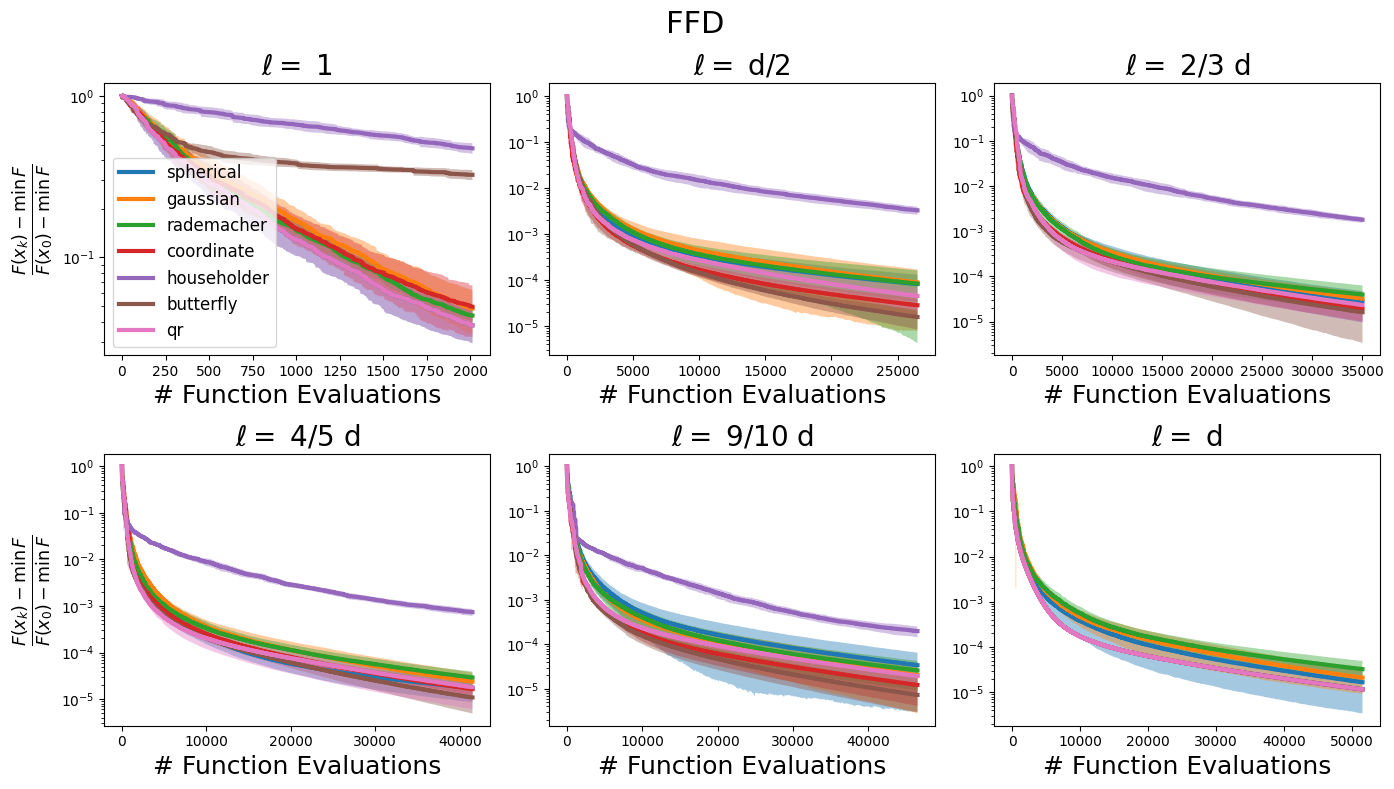

In [50]:
d = 100
num_directions = [1, d//2, round((2/3) * d), round((4/5) * d), round((9/10) * d), d ]
num_dirs_label = ["1", "d/2", "2/3 d", "4/5 d", "9/10 d", 'd']


fig, axes = plt.subplots(2, 3, figsize=(14, 8))

fig.suptitle(method.upper().replace("_","-"), fontsize=22)
axes = axes.flatten()


for i in range(len(num_directions)):
  ax = axes[i]
  ax.set_title(f"$\ell = $ {num_dirs_label[i]}", fontsize=20)
  for dir_type in direction_type:
    mu_vals = []
    min_len = None
    for r in range(5):
      vals, _, f_0, _ = read_result(f"{data_dir}/LeastSquare_{dir_type}_{num_directions[i]}_{L}_{mu}_{d}_1e-07_{r}.csv")
      mu_vals.append(vals)
      if min_len is None or min_len > len(vals):
        min_len = len(vals)
    values = [(np.array(elems[:min_len]) ) / (f_0 ) for elems in mu_vals]
    mu_vals = np.mean(values, axis=0)
    std_vals = np.std(values, axis=0)
    
    ax.plot(range(len(mu_vals)), mu_vals, '-', lw=3, label=dir_type, rasterized=True)
    ax.fill_between(range(len(mu_vals)), mu_vals - std_vals, mu_vals + std_vals, alpha=0.4, rasterized=True)

  ax.set_yscale('log')
  ax.set_xlabel("# Function Evaluations", fontsize=18)
  #ax.set_xscale('log')
  if i == 0:
    ax.legend(fontsize=12)
    ax.set_ylabel("$\\frac{F(x_k) - \\min \\, F}{F(x_0) - \\min \\, F}$", fontsize=18)
  elif i ==3:
    ax.set_ylabel("$\\frac{F(x_k) - \\min \\, F}{F(x_0) - \\min \\, F}$", fontsize=18)

fig.tight_layout()
fig.savefig(f"./linesearch_ls_{method}_{d}_{L}_{mu}.pdf", bbox_inches='tight')

In [104]:
approx_min = np.inf
for i in range(len(num_directions)):
  for dir_type in direction_type:
    mu_vals = []
    min_len = None
    for r in range(5):
      vals, _, f_0, _ = read_result(f"{data_dir}/Synthetic_{dir_type}_{num_directions[i]}_100.0_1.0_100_1e-07_{r}.csv")
      approx_min = min(approx_min, np.min(vals))        
    

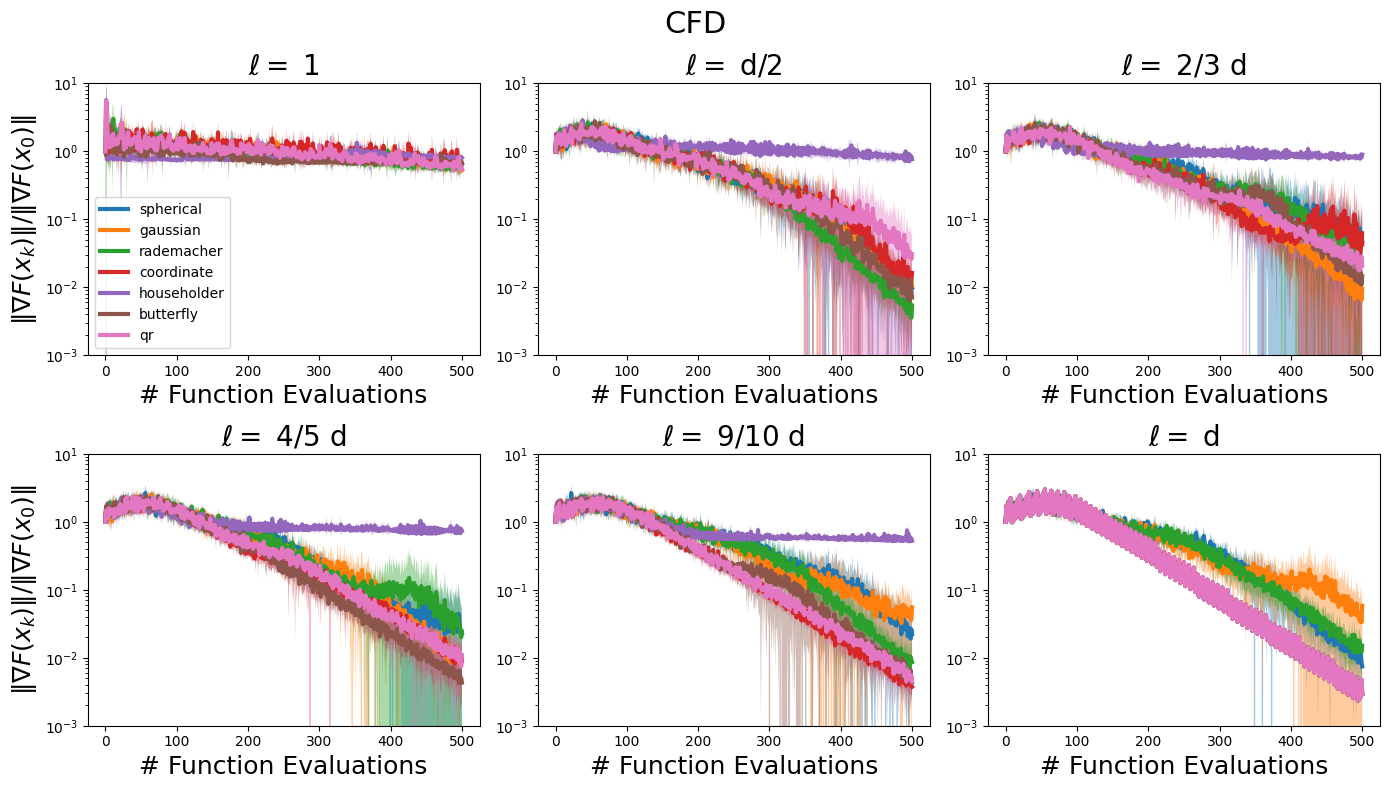

In [ ]:
d = 100
num_directions = [1, d//2, round((2/3) * d), round((4/5) * d), round((9/10) * d), d ]
num_dirs_label = ["1", "d/2", "2/3 d", "4/5 d", "9/10 d", 'd']


fig, axes = plt.subplots(2, 3, figsize=(14, 8))

fig.suptitle(method.upper(), fontsize=22)
axes = axes.flatten()


for i in range(len(num_directions)):
  ax = axes[i]
  ax.set_title(f"$\ell = $ {num_dirs_label[i]}", fontsize=20)
  for dir_type in direction_type:
    values = []
    min_len = None
    for r in range(5):
      vals, _, f_0, grad_norms = read_result(f"{data_dir}/Synthetic_{dir_type}_{num_directions[i]}_100.0_1.0_100_1e-07_{r}.csv")
      values.append(grad_norms )
#      if min_len is None or min_len > len(vals):
#        min_len = len(vals)
   # values = [(np.array(elems[:min_len]) - approx_min) / (f_0 - approx_min) for elems in mu_vals]
    values = np.array(values) / grad_norms[0]
    mu_vals = np.mean(values, axis=0)
    std_vals = np.std(values, axis=0)
    
    ax.plot(range(len(mu_vals)), mu_vals, '-', lw=3, label=dir_type)
    ax.fill_between(range(len(mu_vals)), mu_vals - std_vals, mu_vals + std_vals, alpha=0.4)

  ax.set_yscale('log')
  ax.set_xlabel("# Function Evaluations", fontsize=18)
  ax.set_ylim([1e-3, 1e1])
  
  if i == 0:
    ax.legend()
    ax.set_ylabel("$\| \\nabla F(x_k) \| / \| \\nabla F(x_0) \|$", fontsize=18)
  elif i ==3:
    ax.set_ylabel("$\| \\nabla F(x_k) \| / \| \\nabla F(x_0) \|$", fontsize=18)

fig.tight_layout()
fig.savefig(f"./linesearch_synt_{method}_{d}.pdf", bbox_inches='tight')

## Num Reflectors

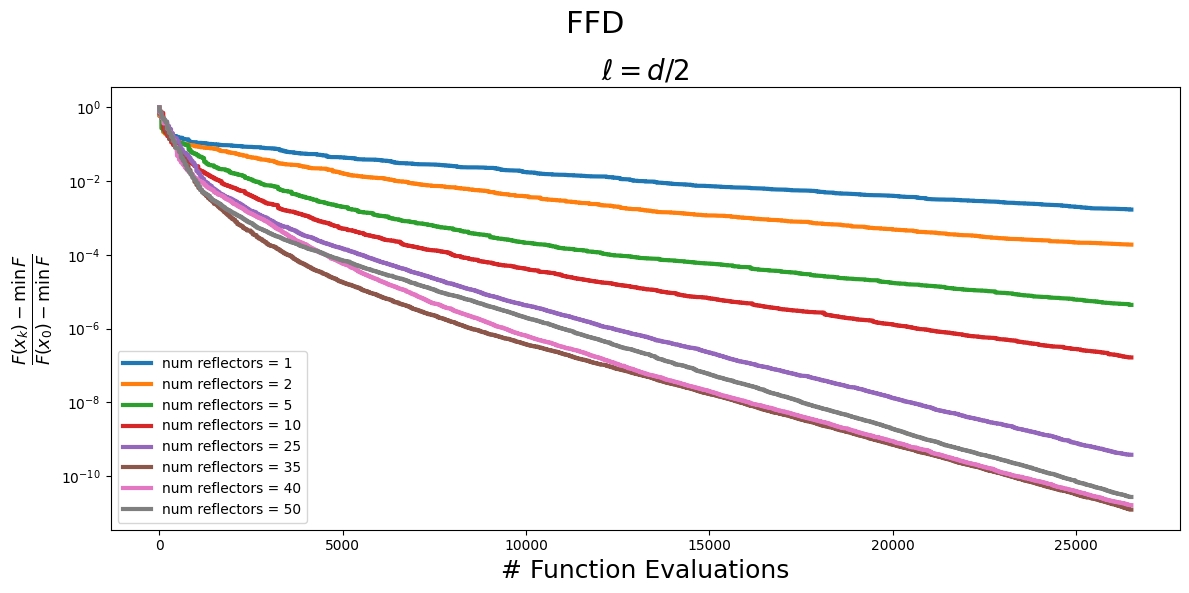

In [71]:
d = 100
num_directions = [1, d//2, round((2/3) * d), round((4/5) * d), round((9/10) * d), d ]
num_dirs_label = ["1", "d/2", "2/3 d", "4/5 d", "9/10 d", 'd']

num_reflectors = [1, 2, 5, 10, 25, 35, 40, 50]

fig, ax = plt.subplots(1, 1, figsize=(12, 6))

fig.suptitle(method.upper(), fontsize=22)
#axes = axes.flatten()
ax.set_title(f"$\ell = d/2$", fontsize=20)
for num_ref in num_reflectors:
  values = []
  min_len = None
  for r in range(1):
    vals, _, f_0, grad_norms = read_result(f"{data_dir}/LeastSquare_NumRef_{num_ref}_{d//2}_100.0_1.0_100_1e-07_{r}.csv")
    values.append(vals )
#      if min_len is None or min_len > len(vals):
#        min_len = len(vals)
  # values = [(np.array(elems[:min_len]) - approx_min) / (f_0 - approx_min) for elems in mu_vals]
  values = np.array(values) / vals[0]
  mu_vals = np.mean(values, axis=0)
  std_vals = np.std(values, axis=0)
  
  ax.plot(range(len(mu_vals)), mu_vals, '-', lw=3, label="num reflectors = {}".format(num_ref), rasterized=True)
#  ax.fill_between(range(len(mu_vals)), mu_vals - std_vals, mu_vals + std_vals, alpha=0.4)

ax.set_yscale('log')
ax.set_xlabel("# Function Evaluations", fontsize=18)
ax.set_ylabel("$\\frac{F(x_k) - \\min \\, F}{F(x_0) - \\min \\, F}$", fontsize=18)

ax.legend()

fig.tight_layout()
fig.savefig(f"./linesearch_ls_numref_{method}_{d}.pdf", bbox_inches='tight')

In [18]:

dimensions = [10, 50, 100]

discretizations = [1e-1, 1e-3, 1e-5]

#d = 100

for (k, d) in enumerate(dimensions):
    for (m_idx, method) in enumerate(methods[:2]):
    #method = methods[1]

        fig, axes = plt.subplots(1, len(discretizations), figsize=(16, 6))

        if k == 0:
            fig.suptitle(method.upper().replace("_","-"), fontsize=24)

        for (i, h) in enumerate(discretizations):
            data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)

            num_directions = list(set(data['l'].values.astype(int)))
            for dir_type in direction_type:
                errors = data[data['directions'] == dir_type ]['err'].values
                times = data[data['directions'] == dir_type ]['time'].values
                print(errors)
                axes[i].boxplot(errors) #num_directions[:-1], mu_err ,'o-', label=dir_type.replace("_", "+"), rasterized=True)
                          
          #      axes[i].plot(num_directions[:-1], mu_err ,'o-', label=dir_type.replace("_", "+"), rasterized=True)
          #      axes[i].fill_between(num_directions[:-1], mu_err - std_err, mu_err + std_err, alpha=0.2, rasterized=True)


            axes[i].set_yscale('log')
            axes[i].set_xlabel("$\\ell$", fontsize=20)    
            if k == 0:
                axes[i].set_title(f"$h = ${h}", fontsize=20)
            
            if i == 0:
                axes[i].set_ylabel("$ \\frac{\\| g(x) - \\nabla F(x) \\|}{\\| \\nabla F(x) \\|}$",fontsize=20)
            if k == 0 and m_idx == 0 and i == 0:
                axes[0].legend(fontsize=14)
        fig.tight_layout()
        fig.savefig(f"./ls_{L}_{mu}_{d}_{method}.pdf", bbox_inches='tight')
        plt.close(fig)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


[2.85416278 1.00165247 3.33384425 1.01141912 1.89031802 2.46700068
 1.22358327 3.33666092 3.09218489 4.82611779 1.16118429 1.54009501
 1.02836271 2.00073335 2.19056707 2.06220067 1.35981991 1.79255922
 1.20492399 1.06670721 2.77935866 1.36012213 1.14023724 1.24851627
 1.19409317 1.83273374 1.37051184 1.13036879 1.29603333 1.0992296
 1.0906184  0.97988392 1.33487198 1.17062694 0.83766052 1.23227394
 1.10431685 0.77812528 0.83721168 1.12109724 0.38726646 0.97260084
 1.04912781 1.59709313 0.62643526 1.15303221 0.74870502 0.77554113
 1.01333242 0.96953483 0.77324763 0.69519427 0.64391461 0.65982991
 0.76983353 0.79756366 1.02629687 1.2688988  0.83469561 0.61640536]
[2.06159196 1.0037447  3.11577007 1.02519063 1.25263584 2.37504855
 1.18670884 4.24189193 2.7139952  2.09926062 1.59830457 1.12610456
 1.72154429 1.31154924 1.04941168 1.83182566 1.11519687 2.62825473
 1.21752467 1.47831353 1.05423026 1.36545776 1.19092387 1.40881956
 1.06053704 1.11187823 0.86221697 2.3271207  1.17301221 0.9727

In [ ]:

dimensions = [10, 50, 100]

discretizations = [1e-1, 1e-3, 1e-5]

#d = 100

for (k, d) in enumerate(dimensions):
    for (m_idx, method) in enumerate(methods[:2]):
    #method = methods[1]

        fig, axes = plt.subplots(1, len(discretizations), figsize=(16, 6))

        if k == 0:
            fig.suptitle(method.upper().replace("_","-"), fontsize=24)

        for (i, h) in enumerate(discretizations):
            data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)

            num_directions = list(set(data['l'].values.astype(int)))
            for dir_type in direction_type:
                errors = data[data['directions'] == dir_type ]['err'].values
                times = data[data['directions'] == dir_type ]['time'].values
                print(errors)
                axes[i].boxplot(errors) #num_directions[:-1], mu_err ,'o-', label=dir_type.replace("_", "+"), rasterized=True)
                          
          #      axes[i].plot(num_directions[:-1], mu_err ,'o-', label=dir_type.replace("_", "+"), rasterized=True)
          #      axes[i].fill_between(num_directions[:-1], mu_err - std_err, mu_err + std_err, alpha=0.2, rasterized=True)


            axes[i].set_yscale('log')
            axes[i].set_xlabel("$\\ell$", fontsize=20)    
            if k == 0:
                axes[i].set_title(f"$h = ${h}", fontsize=20)
            
            if i == 0:
                axes[i].set_ylabel("$ \\frac{\\| g(x) - \\nabla F(x) \\|}{\\| \\nabla F(x) \\|}$",fontsize=20)
            if k == 0 and m_idx == 0 and i == 0:
                axes[0].legend(fontsize=14)
        fig.tight_layout()
        fig.savefig(f"./ls_{L}_{mu}_{d}_{method}.pdf", bbox_inches='tight')
        plt.close(fig)

### l = d Case

Changing h

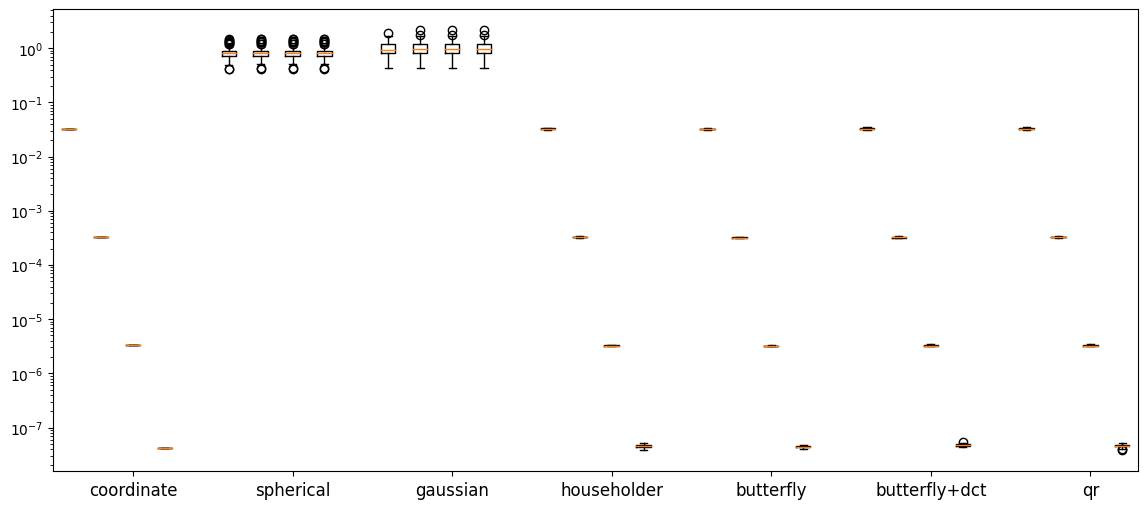

In [204]:

dimensions = [10]#, 50, 100]

results = {dir_type : [[], []] for dir_type in direction_type}

discretizations = [1e-1, 1e-3, 1e-5, 1e-7]
method = methods[0]

d = 10

fig, ax = plt.subplots(figsize=(14, 6))

delta = 5

x_indices = []
x_labels = []

for (i, dir_type) in enumerate(direction_type):
    mu_err, std_err = [], []
    for h in discretizations:   
        data = read_ls_results(data_dir, method, d=d,L=L, mu=mu, h=h)
        data = data[data['directions'] == dir_type]
        mu_err.append(data[data['l'] == d]['err'].values)

    x_indices.append([i * delta + j for j in range(len(discretizations))][2])
    x_labels.append(dir_type.replace("_","+"))# discretizations
    ax.boxplot( mu_err, positions =[i * delta + j for j in range(len(discretizations))], labels=discretizations)

ax.set_xticks(x_indices, x_labels, fontsize=12)

ax.set_yscale("log")
#ax.set_xlabel("Directio")
#ax.legend(loc='upper right',fontsize=12)

## Cutest Benchmark

In [3]:
data_dir = "/data/mrando/fdopt_results/approx_error/noise_0.0"


methods = ['ffd', 'cfd']#, 'opt_ffd', 'opt_cfd']
direction_type = ['coordinate','spherical', 'gaussian', 'householder', 'butterfly', 'butterfly_dct', 'qr']

In [4]:
def get_avg_result(data, dir_type, l_idx):
    data = data[data['directions'] == dir_type]
    data = data[data['l_idx'] == l_idx]
    return data['err'].values, data['time'].values# np.mean(data['err'].values), np.mean(data['time'].values)


h = 1e-5

method = methods[0]


result_files = os.listdir(f"{data_dir}/{method}/cutest/")
fun_names = []
results = {}

for l_idx in range(7):
    for path in result_files:
#        print(path.split("_")[0])
        fun_name = path.split("_")[0] + "[d = {}]".format(path.split("_")[1])
        if fun_name not in results:
            results[fun_name] = {}
            fun_names.append(fun_name)
        if float(path.split("_")[-1].split(".")[0]) == h:
            for dir_type in direction_type:   
                if dir_type not in results[fun_name]:
                    results[fun_name][dir_type] = {l_idx : [[], []]}
                elif l_idx not in results[fun_name][dir_type]:
                    results[fun_name][dir_type][l_idx] = [[], []]
                data = pd.read_csv(f"{data_dir}/{method}/cutest/{path}")
                errors, times = get_avg_result(data, dir_type, l_idx)
                if len(errors) > 0: # == mu_err and mu_err > 0.0:
                    results[fun_name][dir_type][l_idx][0] = np.concatenate((results[fun_name][dir_type][l_idx][0], errors))
                    results[fun_name][dir_type][l_idx][1] = np.concatenate((results[fun_name][dir_type][l_idx][1], times))
    print(f"L_idx = {l_idx}")
#    for dir_type in direction_type:   
#        print("[{}] err = {} +/- {}\ttime = {} +/- {}".format(dir_type, np.mean(results[fun_name][dir_type][0]), np.std(results[dir_type][0]), np.mean(results[dir_type][1]), np.std(results[dir_type][1]) ))


L_idx = 0
L_idx = 1
L_idx = 2
L_idx = 3
L_idx = 4
L_idx = 5
L_idx = 6


In [5]:
print(fun_names, len(fun_names))

['ALJAZZAF[d = 500]', 'ALJAZZAF[d = 1000]', 'ALLINQP[d = 6]', 'ALLINQP[d = 84]', 'ALLINQP[d = 852]', 'ARGLINA[d = 10]', 'ARGLINA[d = 50]', 'ARGLINA[d = 100]', 'ARGLINA[d = 200]', 'ARGLINB[d = 10]', 'ARGLINB[d = 50]', 'ARGLINB[d = 100]', 'ARGLINB[d = 200]', 'ARGLINC[d = 10]', 'ARGLINC[d = 50]', 'ARGLINC[d = 100]', 'ARGLINC[d = 200]', 'ARGTRIGLS[d = 10]', 'ARGTRIGLS[d = 50]', 'ARGTRIGLS[d = 100]', 'ARGTRIGLS[d = 200]', 'ARWHEAD[d = 100]', 'ARWHEAD[d = 500]', 'ARWHEAD[d = 1000]', 'ARWHEAD[d = 5000]', 'BDEXP[d = 100]', 'BDQRTIC[d = 100]', 'BDQRTIC[d = 500]', 'BDQRTIC[d = 1000]', 'BDRY2[d = 21]', 'BIGGSB1[d = 100]', 'BIGGSB1[d = 1000]', 'BIGGSB1[d = 5000]', 'BLOCKQP1[d = 30]', 'BLOCKQP1[d = 210]', 'BLOCKQP1[d = 2010]', 'BLOCKQP2[d = 30]', 'BLOCKQP2[d = 210]', 'BLOCKQP2[d = 2010]', 'BLOCKQP3[d = 30]', 'BLOCKQP3[d = 210]', 'BLOCKQP3[d = 2010]', 'BLOCKQP4[d = 30]', 'BLOCKQP4[d = 210]', 'BLOCKQP4[d = 2010]', 'BLOCKQP5[d = 30]', 'BLOCKQP5[d = 210]', 'BLOCKQP5[d = 2010]', 'BLOWEYA[d = 22]', 'BLOW

In [6]:
colors = ['red', 'orange', 'green', 'blue', 'purple', 'brown', 'gray']

Text(0, 0.5, 'Relative Gradient Approximation Error')

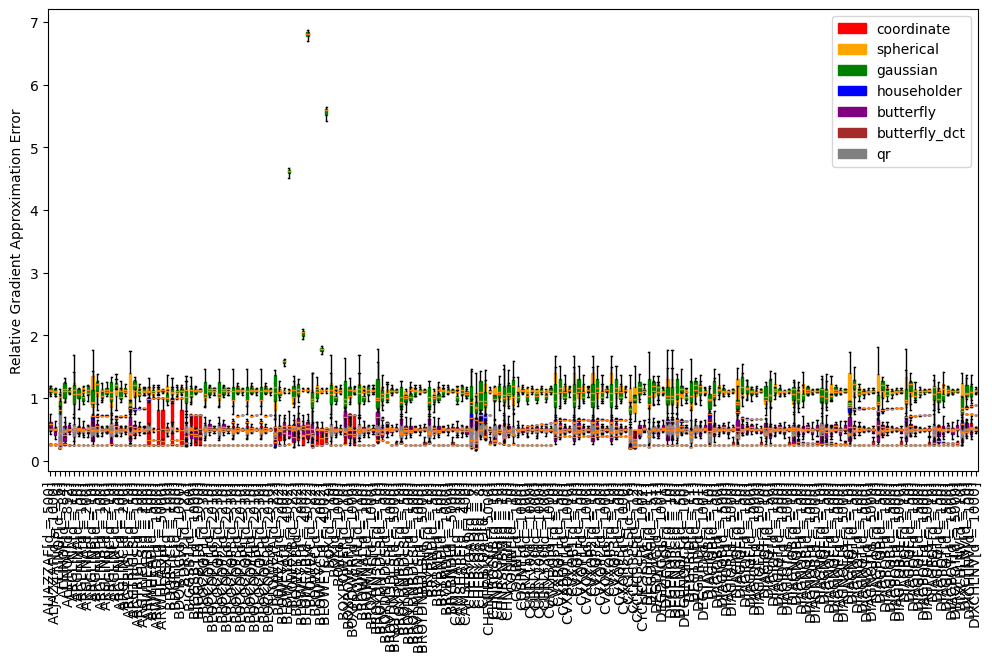

In [10]:
fun_name = fun_names[0]

fig, ax = plt.subplots(figsize=(12, 6))
elements = []
for (i, dir_type) in enumerate(direction_type):
    ris = [results[fun_name][dir_type][3][0] for fun_name in fun_names]


    b = ax.boxplot(ris, patch_artist=True, showfliers=False)
#    print(len(b['boxes']))
    for j in range(len(b['boxes'])):
        b['boxes'][j].set_color(colors[i])
    elements.append(b['boxes'][0])


ax.set_xticks(range(1, len(fun_names) + 1), fun_names, rotation=90)
#ax.set_yscale('log')
#ax.set_ylim([1e-6, 1.0])
ax.legend([element for element in elements], direction_type, loc='upper right')
ax.set_ylabel("Relative Gradient Approximation Error")

coordinate [15.326620401991098, 29.081672576835718, 1.399985010125, 2.8676429438120055, 22.103688019620723, 3.000007107801629, 7.0000169529299, 9.949899429634907, 14.10677384868635, 2.951772459548412, 6.851694150360015, 7.98435355170222, 13.11249134690471, 2.9348853245116944, 7.05520730507749, 6.471496281877212, 13.210128880436887, 2.6109106389148735, 5.740077972898591, 7.211933380993324, 12.575241527537413, 10.893595685472565, 1.1179820321318332, 1.1180103816330749, 1.1180328624556355, 9.754571560525992, 11.747603551201248, 2.2634462524791576, 2.2616943761502895, 3.2931874549718003, 7.900643767165796, 1.0000249996916446, 1.0006248049128357, 5.38519711792772, 14.4568612115166, 44.82186954886559, 5.38519711792772, 14.4568612115166, 44.82186954886559, 5.577995211238063, 16.160831310750858, 32.778352231133354, 5.577995211238063, 16.160831310750858, 32.778352231133354, 5.577995211238063, 16.160831310750858, 32.778352231133354, 1.9572679991283253, 1.0047230364037056, 1.6029902320946778, 3.8

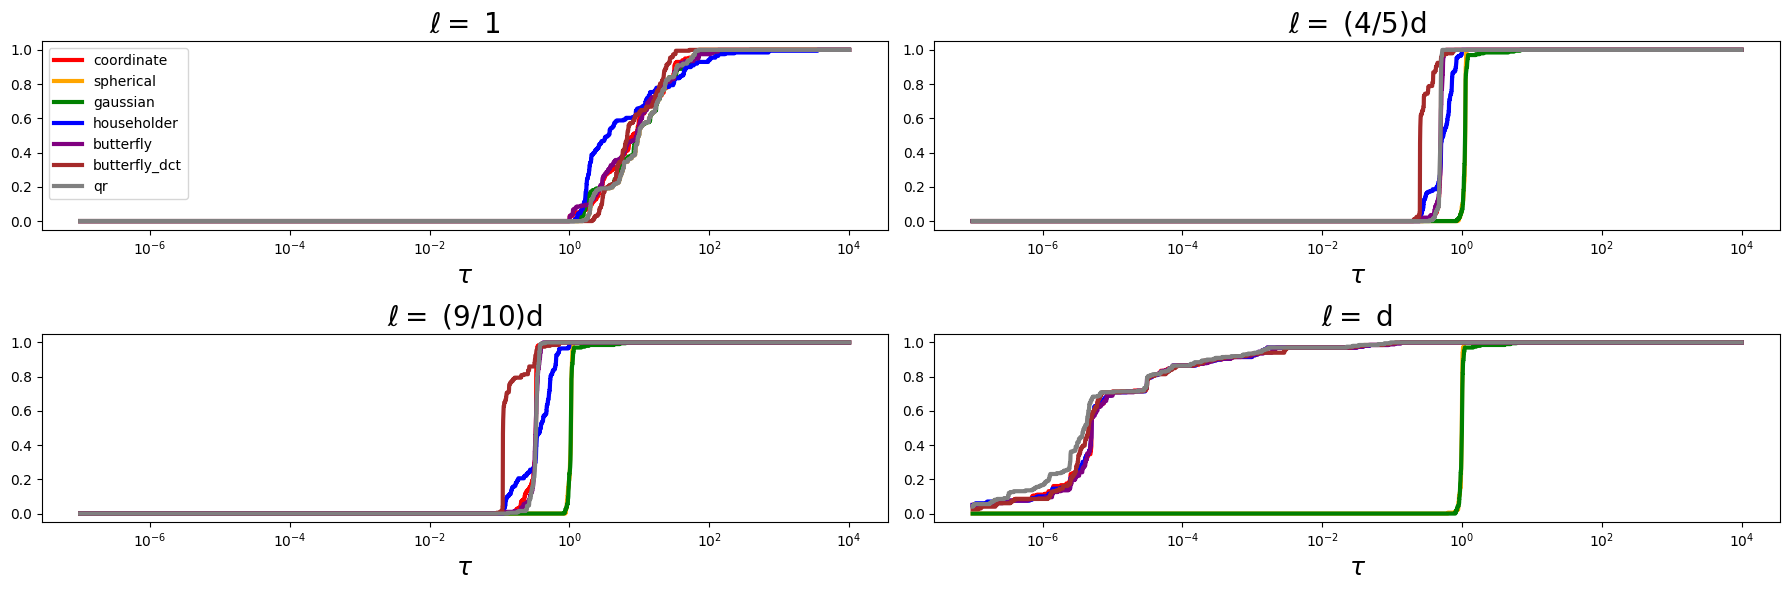

In [11]:
num_directions_labels = ['1', 'd/3', 'd/2', '(4/5)d', '(9/10)d', 'd - 1', 'd']

taus = np.logspace(-7, 4, 10000)

fig, axes = plt.subplots(2, 2, figsize=(18, 6))
axes = axes.flatten()
for (ax, j) in zip(axes, [0, 3, 4, 6]):
    ax.set_title(f"$\\ell = $ {num_directions_labels[j]}", fontsize=20)
    mean_values = {dir_type: [] for dir_type in direction_type}
    performance_profiles = {dir_type: [] for dir_type in direction_type}
    for (i, dir_type) in enumerate(direction_type):
        ris = [np.mean(results[fun_name][dir_type][j][0]) for fun_name in fun_names]
        mean_values[dir_type] = ris
        print(dir_type, mean_values[dir_type])


    for (i, dir_type) in enumerate(direction_type):
        values = np.array(mean_values[dir_type])
        for tau in taus:
            performance_profiles[dir_type].append(np.sum(values < tau) / values.shape[0] )
        
        ax.plot(taus, performance_profiles[dir_type], '-', lw=3, c=colors[i], label=dir_type)

    ax.set_xlabel("$\\tau$", fontsize=18)
#    ax.set_ylabel("fraction of solved problems")
    ax.set_xscale('log')
    if j == 0:
        ax.legend()
        
fig.tight_layout()

fig.savefig("perf_met_cts.pdf", bbox_inches='tight')
#ax.set_xticks(range(1, len(fun_names) + 1), fun_names, rotation=90)
#ax.set_ylabel("Relative Gradient Approximation Error")